In [7]:
from cProfile import label  #Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns



In [8]:
df=pd.read_csv('/Users/ilkekosar/PyCharmMiscProject/florida_fishing_effort/florida_effort_source_records_1981_2025.csv')

In [9]:
df

,status,year,wave,sub_reg,sub_reg_f,st,st_f,mode_fx,mode_fx_f,area_x,...,numvar,pse_e,lower_estrips,upper_estrips,mrip_std_estrips,stat_sig_estrips,source_archive,source_member,period_start,period_end
0,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,3,SHORE,1,...,4.705806e+11,41.6,304747.5,2996243.3,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30
1,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,3,SHORE,5,...,5.252646e+11,40.7,359986.9,3199306.2,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30
2,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,6,PARTY/CHARTER BOAT,1,...,3.616177e+07,40.4,3100.9,26692.4,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30
3,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,6,PARTY/CHARTER BOAT,2,...,2.984398e+07,41.2,2554.7,23990.3,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30
4,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,7,PRIVATE/RENTAL BOAT,1,...,3.098467e+09,56.9,0.0,207061.7,NO,NO,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4191,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,5,CHARTER BOAT,4,...,4.673847e+07,18.0,24517.6,51247.6,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31
4192,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,5,CHARTER BOAT,5,...,1.860066e+07,17.1,16813.8,33766.1,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31
4193,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,7,PRIVATE/RENTAL BOAT,3,...,6.947621e+09,23.8,186886.3,513692.0,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31
4194,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,7,PRIVATE/RENTAL BOAT,4,...,3.067334e+09,23.5,126995.4,343881.1,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,4196.0,2.003510e+03,1.280946e+01,1981.000000,1.993000e+03,2.004000e+03,2.015000e+03,2.025000e+03
wave,4196.0,3.510963e+00,1.704408e+00,1.000000,2.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
sub_reg,4196.0,6.502383e+00,5.000539e-01,6.000000,6.000000e+00,7.000000e+00,7.000000e+00,7.000000e+00
st,4196.0,1.200000e+01,0.000000e+00,12.000000,1.200000e+01,1.200000e+01,1.200000e+01,1.200000e+01
mode_fx,4196.0,5.285272e+00,1.584605e+00,3.000000,3.000000e+00,5.000000e+00,7.000000e+00,7.000000e+00
area_x,4196.0,3.336511e+00,1.534572e+00,1.000000,2.000000e+00,3.000000e+00,5.000000e+00,5.000000e+00
numvar,4196.0,4.238567e+10,1.049006e+11,3203.003659,6.797322e+07,2.156086e+09,2.713436e+10,1.689368e+12
pse_e,4196.0,2.808420e+01,1.680539e+01,6.100000,1.820000e+01,2.310000e+01,3.070000e+01,1.330000e+02
lower_estrips,4196.0,2.755414e+05,3.837713e+05,0.000000,1.170575e+04,8.885795e+04,4.064622e+05,2.439472e+06
upper_estrips,4196.0,7.479756e+05,9.984202e+05,175.600000,5.196573e+04,2.838768e+05,1.097553e+06,6.346645e+06


In [11]:
import pandas as pd

# Keep the original values for reference.
df["estrips_original"] = df["estrips"].copy()

s = df["estrips"].astype("string").str.strip()
s = s.replace("", pd.NA)

df["estrips"] = pd.to_numeric(
    s.str.replace(",", "", regex=False),
    errors="raise"
).astype("float64")

print(df[["estrips_original", "estrips"]].head())
print(df["estrips"].dtype)
print("Non-missing effort values:", df["estrips"].notna().sum())

  estrips_original    estrips
0        1,650,495  1650495.0
1        1,779,647  1779647.0
2           14,897    14897.0
3           13,272    13272.0
4           97,890    97890.0
float64
Non-missing effort values: 4196


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,4196.0,2.003510e+03,1.280946e+01,1981.000000,1.993000e+03,2.004000e+03,2.015000e+03,2.025000e+03
wave,4196.0,3.510963e+00,1.704408e+00,1.000000,2.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
sub_reg,4196.0,6.502383e+00,5.000539e-01,6.000000,6.000000e+00,7.000000e+00,7.000000e+00,7.000000e+00
st,4196.0,1.200000e+01,0.000000e+00,12.000000,1.200000e+01,1.200000e+01,1.200000e+01,1.200000e+01
mode_fx,4196.0,5.285272e+00,1.584605e+00,3.000000,3.000000e+00,5.000000e+00,7.000000e+00,7.000000e+00
area_x,4196.0,3.336511e+00,1.534572e+00,1.000000,2.000000e+00,3.000000e+00,5.000000e+00,5.000000e+00
estrips,4196.0,5.111598e+05,6.824246e+05,65.000000,3.328100e+04,1.868945e+05,7.579475e+05,4.253897e+06
numvar,4196.0,4.238567e+10,1.049006e+11,3203.003659,6.797322e+07,2.156086e+09,2.713436e+10,1.689368e+12
pse_e,4196.0,2.808420e+01,1.680539e+01,6.100000,1.820000e+01,2.310000e+01,3.070000e+01,1.330000e+02
lower_estrips,4196.0,2.755414e+05,3.837713e+05,0.000000,1.170575e+04,8.885795e+04,4.064622e+05,2.439472e+06


In [13]:
df.groupby('year')['estrips'].describe()

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
1981,69.0,358276.913043,545169.039679,592.0,39445.00,123538.0,431112.00,2495965.0
1982,84.0,354662.309524,603416.801862,1534.0,46660.50,116185.5,357127.50,2883801.0
1983,86.0,419470.046512,654540.626798,489.0,49034.50,104354.5,410546.50,2975209.0
1984,89.0,478613.078652,742435.761228,553.0,46374.00,115528.0,576603.00,3094695.0
1985,86.0,405179.267442,587504.117618,664.0,43733.25,136251.0,430161.50,2530811.0
1986,86.0,483372.965116,786227.125356,3116.0,41969.00,154228.0,456870.25,4253897.0
1987,87.0,398786.597701,596821.409129,65.0,56113.00,165836.0,436022.00,2577735.0
1988,86.0,465875.732558,674482.943877,560.0,35812.00,169204.5,543754.00,2732184.0
1989,91.0,404279.791209,530367.274837,74.0,41004.00,179539.0,461729.50,2179916.0


In [14]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

Columns: ['status', 'year', 'wave', 'sub_reg', 'sub_reg_f', 'st', 'st_f', 'mode_fx', 'mode_fx_f', 'area_x', 'area_x_f', 'estrips', 'numvar', 'pse_e', 'lower_estrips', 'upper_estrips', 'mrip_std_estrips', 'stat_sig_estrips', 'source_archive', 'source_member', 'period_start', 'period_end', 'estrips_original']

st: [12]

sub_reg: [6 7]

mode_fx: [3 6 7 5]

area_x: [1 5 2 3 4]

Rows with invalid/missing dates or effort: 0

Available series:
                                  series  observations  first_year  last_year  mean_effort
st=12 | sub_reg=6 | mode_fx=3 | area_x=1           269        1981       2025 1.965620e+06
st=12 | sub_reg=6 | mode_fx=3 | area_x=5           269        1981       2025 1.434702e+06
st=12 | sub_reg=6 | mode_fx=5 | area_x=1           240        1986       2025 1.654115e+04
st=12 | sub_reg=6 | mode_fx=5 | area_x=2           240        1986       2025 2.410600e+04
st=12 | sub_reg=6 | mode_fx=5 | area_x=5           202        1988       2025 7.488045e+03
st=12 | sub_r

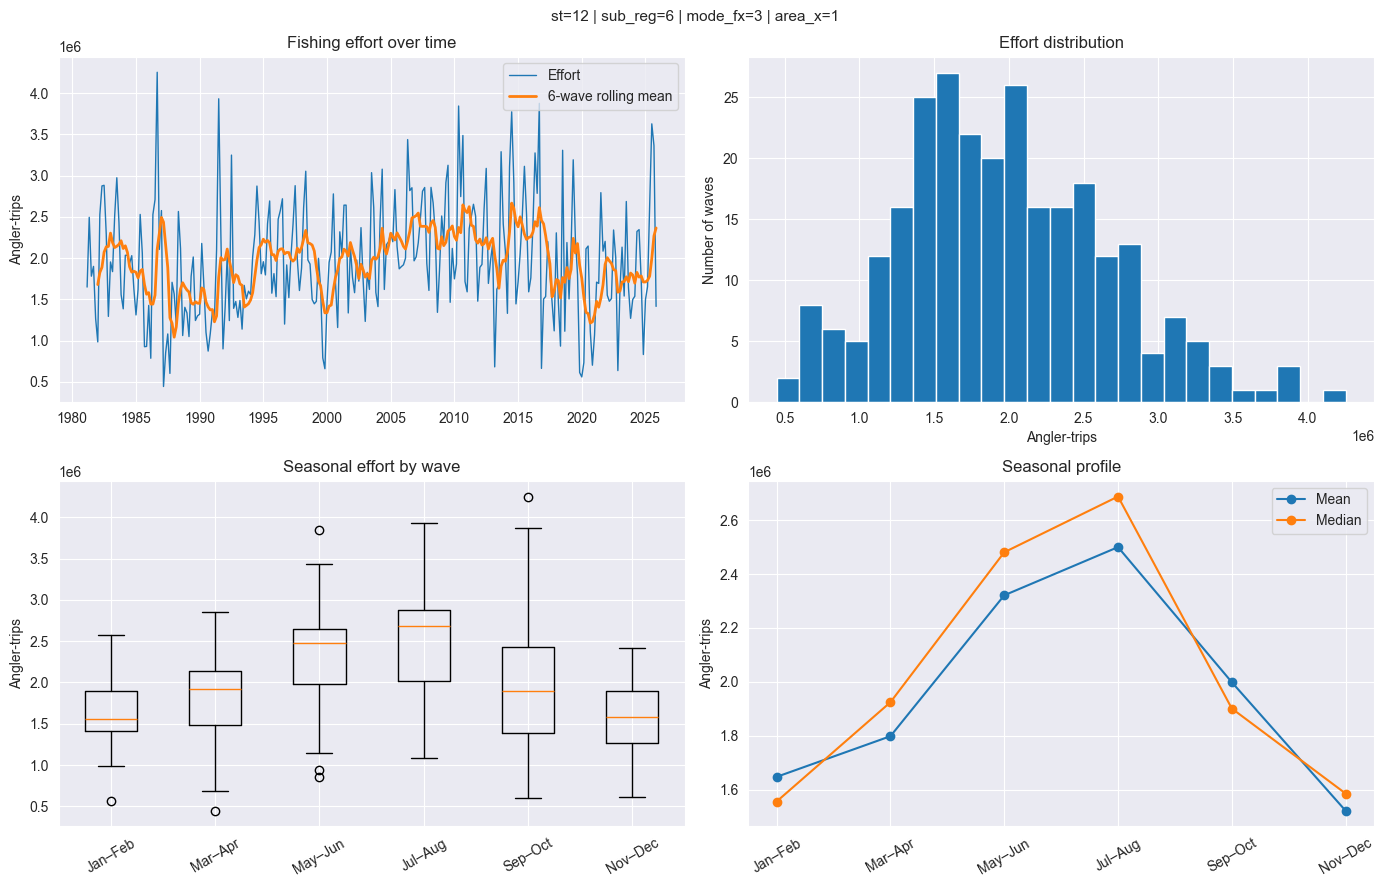


Seasonal summary:
      count          mean     median            std
wave                                               
1        44  1.647384e+06  1555863.0  405255.979762
2        45  1.798260e+06  1924335.0  532020.043093
3        45  2.321057e+06  2480713.0  659369.658971
4        45  2.499881e+06  2687578.0  655565.353341
5        45  1.998480e+06  1900914.0  831701.129753
6        45  1.521589e+06  1585528.0  483142.991003


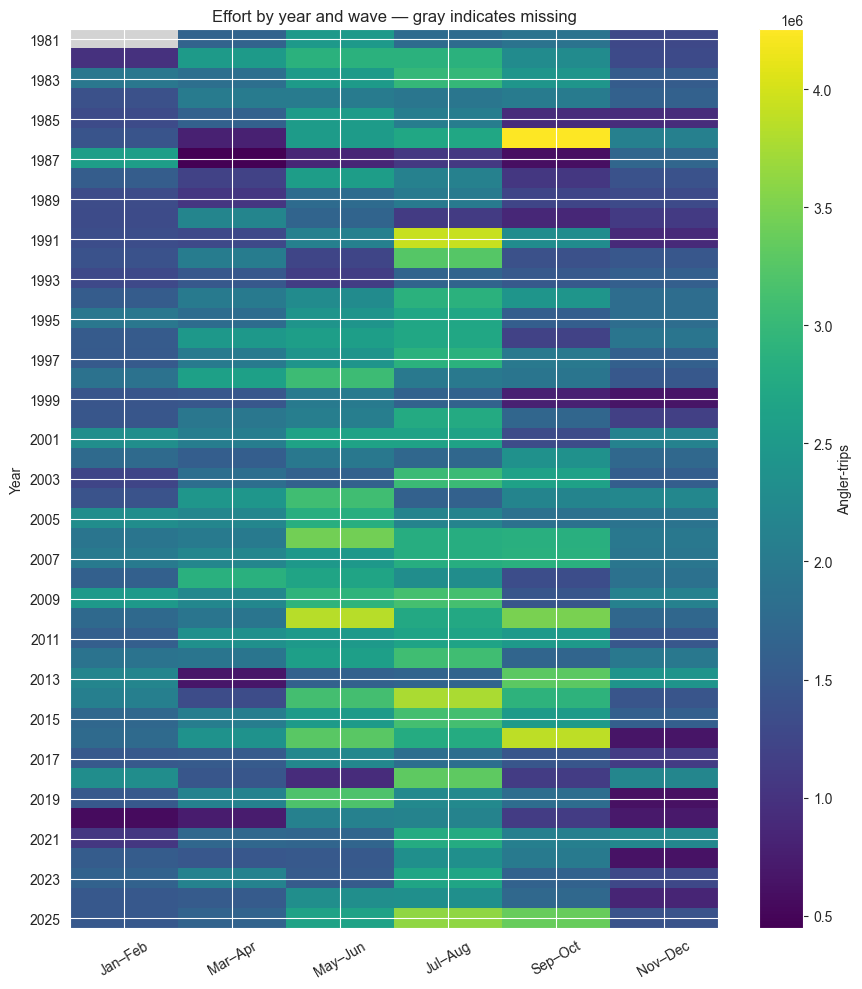


Longest complete segment: 1981-03-01 00:00:00 to 2025-11-01 00:00:00 (269 waves)


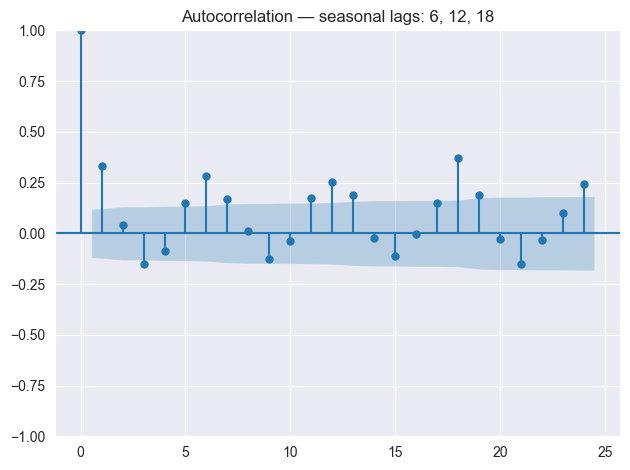

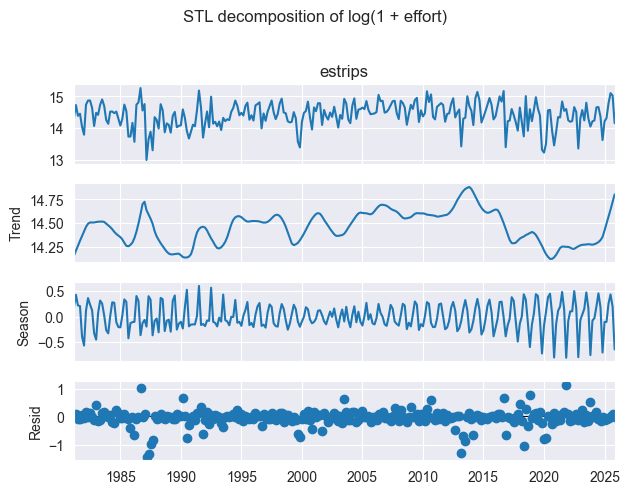


Percent standard error summary:
count    269.000000
mean      25.941298
std        9.108902
min       13.158201
25%       20.374362
50%       23.760497
75%       28.561327
max       98.058638
Name: effort_pse, dtype: float64


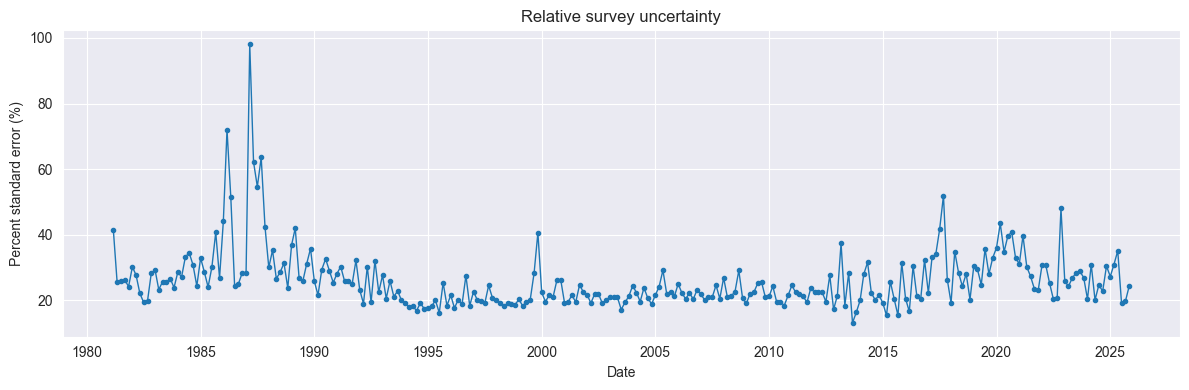

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

# ============================================================
# 1. CLEAN AND INSPECT
# ============================================================
data = df.copy()
data.columns = data.columns.str.strip().str.lower()

required = ["year", "wave", "estrips"]
missing = set(required) - set(data.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in required + ["numvar"]:
    if col in data:
        data[col] = pd.to_numeric(data[col], errors="coerce")

print("Columns:", data.columns.tolist())

# Inspect geography, fishing mode, and aggregation codes.
code_cols = [
    c for c in ["st", "sub_reg", "fl_reg", "mode_fx", "area_x", "level"]
    if c in data.columns
]
for col in code_cols:
    print(f"\n{col}: {data[col].dropna().unique()}")

invalid = (
    data["year"].isna()
    | ~data["wave"].isin(range(1, 7))
    | data["estrips"].isna()
    | data["estrips"].lt(0)
)
print("\nRows with invalid/missing dates or effort:", invalid.sum())
data = data.loc[~invalid].copy()

data[["year", "wave"]] = data[["year", "wave"]].astype(int)

data["date"] = pd.to_datetime({
    "year": data["year"],
    "month": 2 * data["wave"] - 1,
    "day": 1,
})

# Missing grouping codes remain explicit.
for col in code_cols:
    data[col] = data[col].astype("string").fillna("missing")

if code_cols:
    data["series"] = data[code_cols].apply(
        lambda row: " | ".join(f"{c}={row[c]}" for c in code_cols),
        axis=1
    )
else:
    data["series"] = "effort"

duplicates = data.duplicated(["series", "date"], keep=False)
if duplicates.any():
    print(data.loc[duplicates].head(20).to_string(index=False))
    raise ValueError(
        "Multiple records per series/wave. Select one consistent "
        "aggregation level or inspect additional identifying columns."
    )

if "numvar" in data:
    data["effort_se"] = np.sqrt(data["numvar"].where(data["numvar"] >= 0))
    data["effort_pse"] = (
        100 * data["effort_se"]
        / data["estrips"].where(data["estrips"] > 0)
    )

print("\nAvailable series:")
series_table = (
    data.groupby("series")
    .agg(
        observations=("estrips", "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        mean_effort=("estrips", "mean"),
    )
    .reset_index()
)
print(series_table.to_string(index=False))

# ============================================================
# 2. SELECT ONE SERIES
# ============================================================
# Change the index after inspecting the table above.
SERIES_INDEX = 0
selected = series_table.iloc[SERIES_INDEX]["series"]
print("\nAnalyzing:", selected)

s = data.loc[data["series"].eq(selected)].sort_values("date").copy()

# Complete calendar: missing waves stay NaN, never become zero.
calendar = pd.date_range(
    s["date"].min(), s["date"].max(), freq="2MS"
)
ts = s.set_index("date")["estrips"].reindex(calendar)
ts.index.name = "date"

print("\nEffort summary:")
print(ts.describe())
print("\nMissing waves:", ts.isna().sum())
print("Missing dates:", ts.index[ts.isna()].strftime("%Y-%m").tolist())

# ============================================================
# 3. TREND, DISTRIBUTION, AND SEASONALITY
# ============================================================
wave_labels = {
    1: "Jan–Feb", 2: "Mar–Apr", 3: "May–Jun",
    4: "Jul–Aug", 5: "Sep–Oct", 6: "Nov–Dec",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(ts.index, ts, linewidth=1, label="Effort")
axes[0, 0].plot(
    ts.index, ts.rolling(6, min_periods=6).mean(),
    linewidth=2, label="6-wave rolling mean"
)
axes[0, 0].set(title="Fishing effort over time", ylabel="Angler-trips")
axes[0, 0].legend()

axes[0, 1].hist(s["estrips"], bins=25, edgecolor="white")
axes[0, 1].set(title="Effort distribution", xlabel="Angler-trips",
               ylabel="Number of waves")

groups = [s.loc[s["wave"].eq(w), "estrips"].values for w in range(1, 7)]
axes[1, 0].boxplot(groups)
axes[1, 0].set_xticks(range(1, 7))
axes[1, 0].set_xticklabels(wave_labels.values(), rotation=30)
axes[1, 0].set(title="Seasonal effort by wave", ylabel="Angler-trips")

seasonal = (
    s.groupby("wave")["estrips"]
    .agg(["count", "mean", "median", "std"])
    .reindex(range(1, 7))
)
axes[1, 1].plot(
    range(1, 7), seasonal["mean"], marker="o", label="Mean"
)
axes[1, 1].plot(
    range(1, 7), seasonal["median"], marker="o", label="Median"
)
axes[1, 1].set_xticks(range(1, 7))
axes[1, 1].set_xticklabels(wave_labels.values(), rotation=30)
axes[1, 1].set(title="Seasonal profile", ylabel="Angler-trips")
axes[1, 1].legend()

fig.suptitle(selected, fontsize=11)
plt.tight_layout()
plt.show()

print("\nSeasonal summary:")
print(seasonal)

# ============================================================
# 4. YEAR × WAVE HEATMAP
# ============================================================
heat = s.pivot(index="year", columns="wave", values="estrips")
heat = heat.reindex(
    index=range(s["year"].min(), s["year"].max() + 1),
    columns=range(1, 7),
)

fig, ax = plt.subplots(figsize=(9, 10))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")

im = ax.imshow(
    np.ma.masked_invalid(heat.to_numpy(dtype=float)),
    aspect="auto", cmap=cmap
)
ax.set_xticks(range(6))
ax.set_xticklabels(wave_labels.values(), rotation=30)
positions = np.arange(0, len(heat), 2)
ax.set_yticks(positions)
ax.set_yticklabels(heat.index[positions])
ax.set(title="Effort by year and wave — gray indicates missing",
       ylabel="Year")
fig.colorbar(im, ax=ax, label="Angler-trips")
plt.tight_layout()
plt.show()

# ============================================================
# 5. AUTOCORRELATION AND STL
# ============================================================
# Use the longest uninterrupted segment; do not close gaps
# by dropping missing dates or invent values by interpolation.
segment_id = ts.isna().cumsum()
segments = [
    part.dropna() for _, part in ts.groupby(segment_id)
    if part.notna().any()
]
complete = max(segments, key=len)

print(
    "\nLongest complete segment:",
    complete.index.min(), "to", complete.index.max(),
    f"({len(complete)} waves)"
)

if len(complete) >= 18:
    plot_acf(complete, lags=min(24, len(complete) // 2 - 1))
    plt.title("Autocorrelation — seasonal lags: 6, 12, 18")
    plt.tight_layout()
    plt.show()

    # Log scale accommodates seasonality that grows with effort.
    result = STL(np.log1p(complete), period=6, robust=True).fit()
    result.plot()
    plt.suptitle("STL decomposition of log(1 + effort)", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Too few consecutive waves for the selected STL/ACF analysis.")

# ============================================================
# 6. SURVEY UNCERTAINTY
# ============================================================
if "effort_pse" in s:
    print("\nPercent standard error summary:")
    print(s["effort_pse"].describe())

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(s["date"], s["effort_pse"], marker=".", linewidth=1)
    ax.set(title="Relative survey uncertainty",
           ylabel="Percent standard error (%)", xlabel="Date")
    plt.tight_layout()
    plt.show()

In [16]:
raw = df.copy()
raw.columns = raw.columns.str.strip().str.lower()

print("Original dataframe shape:", raw.shape)
print("Columns:", raw.columns.tolist())

for col in ["year", "wave", "estrips", "st",
            "sub_reg", "mode_fx", "area_x"]:
    if col in raw:
        print(f"\n{col}:")
        print(raw[col].value_counts(dropna=False).head(15))

# Compare records available with records containing numeric effort.
year = pd.to_numeric(raw["year"], errors="coerce")
effort = pd.to_numeric(raw["estrips"], errors="coerce")

audit = pd.DataFrame({
    "year": year,
    "numeric_effort": effort.notna()
}).groupby("year").agg(
    total_rows=("numeric_effort", "size"),
    rows_with_effort=("numeric_effort", "sum")
)

print("\nCoverage before EDA filtering:")
print(audit.to_string())

print("\nExample source rows:")
print(raw.head(5).to_string(index=False))

Original dataframe shape: (4196, 23)
Columns: ['status', 'year', 'wave', 'sub_reg', 'sub_reg_f', 'st', 'st_f', 'mode_fx', 'mode_fx_f', 'area_x', 'area_x_f', 'estrips', 'numvar', 'pse_e', 'lower_estrips', 'upper_estrips', 'mrip_std_estrips', 'stat_sig_estrips', 'source_archive', 'source_member', 'period_start', 'period_end', 'estrips_original']

year:
year
2003    96
2004    96
2006    96
2007    96
2008    96
2009    96
2010    96
2011    96
2012    96
2013    96
2014    96
2015    96
2016    96
2017    96
2018    96
Name: count, dtype: int64

wave:
wave
4    704
2    703
6    703
5    702
3    699
1    685
Name: count, dtype: int64

estrips:
estrips
11459.0     3
363323.0    2
9379.0      2
6388.0      2
18221.0     2
276.0       2
3345.0      2
11722.0     2
18292.0     2
17145.0     2
10813.0     2
62974.0     2
8974.0      2
10546.0     2
33872.0     2
Name: count, dtype: int64

st:
st
12    4196
Name: count, dtype: int64

sub_reg:
sub_reg
7    2108
6    2088
Name: count, dtype: in

In [17]:
import numpy as np
import pandas as pd

data = df.copy()
data.columns = data.columns.str.strip().str.lower()

# Remove thousands separators before numeric conversion.
numeric_cols = [
    "year", "wave", "st", "sub_reg", "mode_fx", "area_x",
    "estrips", "numvar", "pse_e", "lower_estrips", "upper_estrips"
]

for col in numeric_cols:
    if col in data:
        cleaned = (
            data[col].astype("string")
            .str.replace(",", "", regex=False)
            .str.strip()
        )
        data[col] = pd.to_numeric(cleaned, errors="coerce")

print("Numeric effort values recovered:", data["estrips"].notna().sum())

# Check the descriptive labels supplied by NOAA.
print(
    data[["sub_reg", "sub_reg_f", "mode_fx", "mode_fx_f",
          "area_x", "area_x_f"]]
    .drop_duplicates()
    .sort_values(["sub_reg", "mode_fx", "area_x"])
    .to_string(index=False)
)

# Select ONE consistently defined series.
COAST = 6       # 6 = East Florida; 7 = West Florida
MODE = 7        # 7 = private/rental boat; 3 = shore
AREA = 5        # 5 = inland saltwater/brackish waters

selected = data.loc[
    data["st"].eq(12)
    & data["sub_reg"].eq(COAST)
    & data["mode_fx"].eq(MODE)
    & data["area_x"].eq(AREA)
    & data["wave"].isin(range(1, 7))
    & data["year"].notna()
].copy()

selected["date"] = pd.to_datetime({
    "year": selected["year"].astype(int),
    "month": selected["wave"].astype(int) * 2 - 1,
    "day": 1,
})

if selected.empty:
    raise ValueError("No records match this selection.")

if selected["date"].duplicated().any():
    raise ValueError("Duplicate waves found; inspect before modeling.")

ts = selected.set_index("date")["estrips"].sort_index()
ts = ts.reindex(
    pd.date_range(ts.index.min(), ts.index.max(), freq="2MS")
)
ts.index.name = "date"
ts.name = "effort"

print("\nDate range:", ts.index.min(), "to", ts.index.max())
print("Observed waves:", ts.notna().sum())
print("Missing waves:", ts.isna().sum())
print(ts.head(12))

Numeric effort values recovered: 4196
 sub_reg       sub_reg_f  mode_fx           mode_fx_f  area_x         area_x_f
       6  SOUTH ATLANTIC        3               SHORE       1  OCEAN (<= 3 MI)
       6  SOUTH ATLANTIC        3               SHORE       5           INLAND
       6  SOUTH ATLANTIC        5        CHARTER BOAT       1  OCEAN (<= 3 MI)
       6  SOUTH ATLANTIC        5        CHARTER BOAT       2   OCEAN (> 3 MI)
       6  SOUTH ATLANTIC        5        CHARTER BOAT       5           INLAND
       6  SOUTH ATLANTIC        6  PARTY/CHARTER BOAT       1  OCEAN (<= 3 MI)
       6  SOUTH ATLANTIC        6  PARTY/CHARTER BOAT       2   OCEAN (> 3 MI)
       6  SOUTH ATLANTIC        6  PARTY/CHARTER BOAT       5           INLAND
       6  SOUTH ATLANTIC        7 PRIVATE/RENTAL BOAT       1  OCEAN (<= 3 MI)
       6  SOUTH ATLANTIC        7 PRIVATE/RENTAL BOAT       2   OCEAN (> 3 MI)
       6  SOUTH ATLANTIC        7 PRIVATE/RENTAL BOAT       5           INLAND
       7 GULF 

Training: 1981-03-01 00:00:00 to 2020-11-01 00:00:00
Testing:  2021-01-01 00:00:00 to 2025-11-01 00:00:00

Common evaluation waves: 30 of 30

Baseline performance:
                 model        MAE       RMSE     R2  seasonal_MASE  n_test
        seasonal_naive 175827.700 218330.010  0.308          1.457      30
             last_wave 275734.633 352967.443 -0.808          2.285      30
training_seasonal_mean 401631.675 437079.403 -1.772          3.328      30


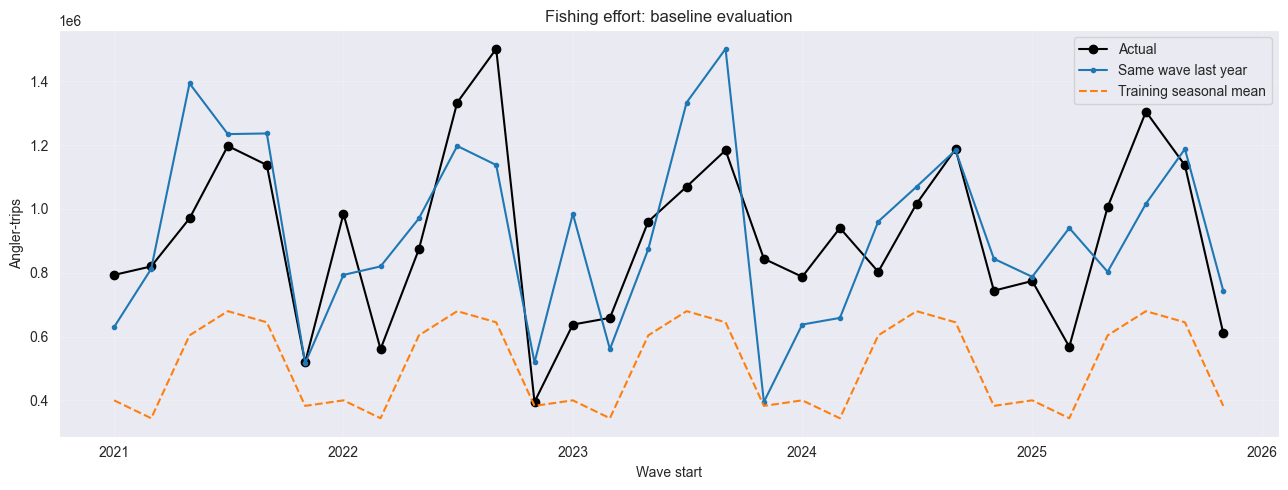

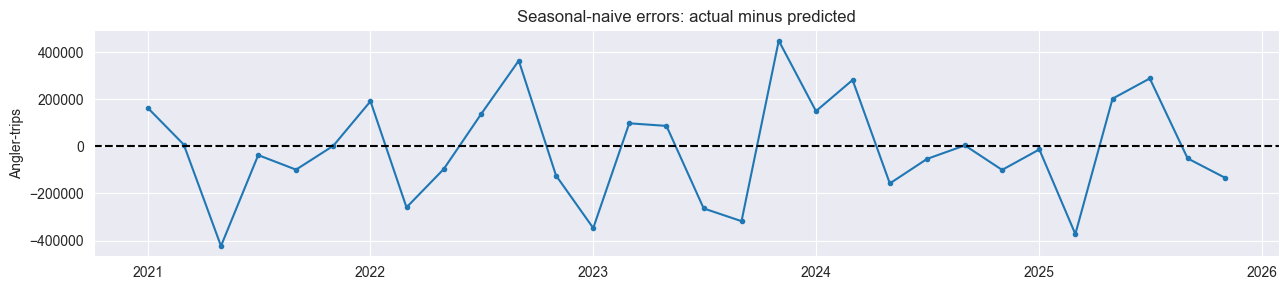

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# ============================================================
# 1. VALIDATE ONE SERIES
# ============================================================
y = pd.to_numeric(ts.copy(), errors="raise").sort_index()
y.index = pd.to_datetime(y.index)
y.name = "effort"

if y.index.has_duplicates:
    raise ValueError("Select one series with one record per wave.")

if not (
    (y.index.day == 1)
    & y.index.month.isin([1, 3, 5, 7, 9, 11])
).all():
    raise ValueError("Expected wave-start dates: Jan, Mar, May, Jul, Sep, Nov.")

calendar = pd.date_range(y.index.min(), y.index.max(), freq="2MS")
y = y.reindex(calendar)  # Keep missing waves as NaN.

if y.dropna().lt(0).any():
    raise ValueError("Effort cannot be negative.")

# ============================================================
# 2. TRAIN / TEST SPLIT — FINAL FIVE CALENDAR YEARS
# ============================================================
test_start_year = y.index.max().year - 4
test_start = pd.Timestamp(test_start_year, 1, 1)

train = y.loc[y.index < test_start]
test = y.loc[y.index >= test_start]

if train.notna().sum() < 12:
    raise ValueError("Need at least two years of observed training data.")

print("Training:", train.index.min(), "to", train.index.max())
print("Testing: ", test.index.min(), "to", test.index.max())

# ============================================================
# 3. THREE SIMPLE BASELINES
# ============================================================
# Rolling one-wave-ahead evaluation:
# at each test wave, previous observed effort is available.
predictions = pd.DataFrame({
    "actual": test,
    "last_wave": y.shift(1).reindex(test.index),
    "seasonal_naive": y.shift(6).reindex(test.index),
})

# Seasonal means are fitted only on training data.
train_waves = (train.index.month + 1) // 2
wave_means = train.groupby(train_waves).mean()

test_waves = (test.index.month + 1) // 2
predictions["training_seasonal_mean"] = [
    wave_means.get(wave, np.nan) for wave in test_waves
]

# Compare models on the same observed dates.
scored = predictions.dropna().copy()
print("\nCommon evaluation waves:", len(scored), "of", len(test))

if len(scored) < 2:
    raise ValueError("Too few complete waves for evaluation.")

# ============================================================
# 4. METRICS
# ============================================================
# Seasonal MASE denominator uses training data only.
scale = (train - train.shift(6)).abs().mean()

rows = []
for model in predictions.columns.drop("actual"):
    actual = scored["actual"]
    predicted = scored[model]

    mae = mean_absolute_error(actual, predicted)

    rows.append({
        "model": model,
        "MAE": mae,
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "seasonal_MASE": (
            mae / scale if pd.notna(scale) and scale > 0 else np.nan
        ),
        "n_test": len(scored),
    })

results = pd.DataFrame(rows).sort_values("MAE")
print("\nBaseline performance:")
print(results.round(3).to_string(index=False))

# ============================================================
# 5. ACTUAL VS PREDICTED
# ============================================================
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    predictions.index, predictions["actual"],
    color="black", marker="o", label="Actual"
)
ax.plot(
    predictions.index, predictions["seasonal_naive"],
    marker=".", label="Same wave last year"
)
ax.plot(
    predictions.index, predictions["training_seasonal_mean"],
    linestyle="--", label="Training seasonal mean"
)

ax.set(
    title="Fishing effort: baseline evaluation",
    xlabel="Wave start",
    ylabel="Angler-trips",
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ============================================================
# 6. SEASONAL-NAIVE ERRORS
# ============================================================
seasonal_errors = predictions[
    ["actual", "seasonal_naive"]
].dropna().copy()

seasonal_errors["error"] = (
    seasonal_errors["actual"] - seasonal_errors["seasonal_naive"]
)

fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(seasonal_errors.index, seasonal_errors["error"], marker=".")
ax.axhline(0, color="black", linestyle="--")
ax.set(
    title="Seasonal-naive errors: actual minus predicted",
    ylabel="Angler-trips",
)
plt.tight_layout()
plt.show()

Epochs: 26
         model        MAE       RMSE  seasonal_MASE  n_test
        bilstm 172517.515 199805.773          1.429      30
seasonal_naive 175827.700 218330.010          1.457      30
Common scored waves: 30 of 30


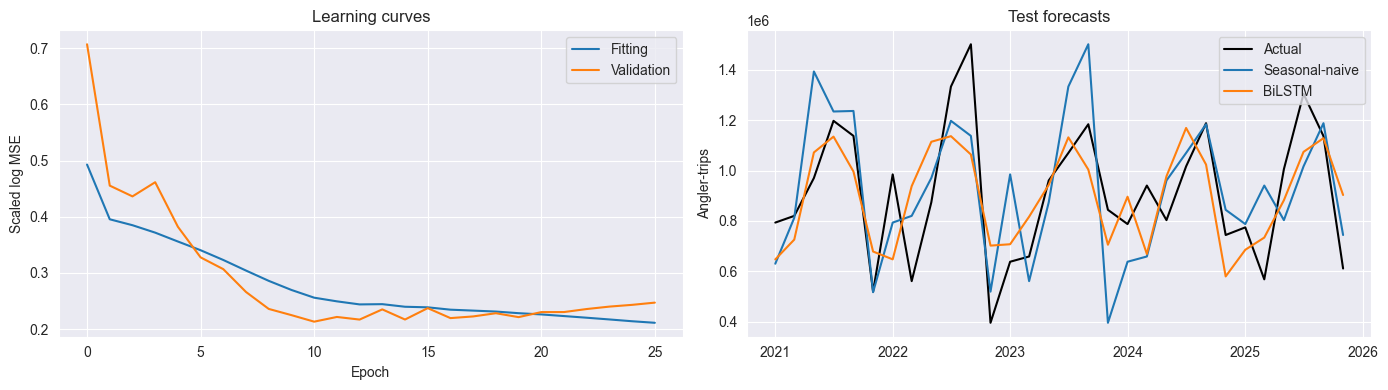

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Bidirectional, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

LOOKBACK = 12
VALIDATION_WAVES = 18  # Last three years of training, for early stopping.

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------
# `y` must retain its regular two-month calendar and missing waves.
y = y.astype(float).sort_index()
train_y = y.reindex(train.index)
test_y = y.reindex(test.index)

if len(train_y) <= LOOKBACK + VALIDATION_WAVES:
    raise ValueError("Insufficient training history for this setup.")

validation_start = train_y.index[-VALIDATION_WAVES]
fit_history = train_y.loc[train_y.index < validation_start].dropna()

if fit_history.empty:
    raise ValueError("No observed data before validation.")

# Fit transformation only on the pre-validation training period.
scaler = StandardScaler()
scaler.fit(np.log1p(fit_history.to_numpy()).reshape(-1, 1))

def transform(values):
    values = np.asarray(values, dtype=float)
    return scaler.transform(
        np.log1p(values).reshape(-1, 1)
    ).ravel()

def make_windows(series):
    X, target, dates = [], [], []
    values = series.to_numpy(dtype=float)

    for i in range(LOOKBACK, len(series)):
        window = values[i - LOOKBACK:i]
        outcome = values[i]

        # Skip incomplete windows; never close calendar gaps.
        if not np.isfinite(window).all() or not np.isfinite(outcome):
            continue

        X.append(transform(window))
        target.append(transform([outcome])[0])
        dates.append(series.index[i])

    return (
        np.asarray(X, dtype=np.float32).reshape(-1, LOOKBACK, 1),
        np.asarray(target, dtype=np.float32),
        pd.DatetimeIndex(dates),
    )

X, target, dates = make_windows(train_y)
fit_mask = dates < validation_start
val_mask = dates >= validation_start

if fit_mask.sum() < 24 or val_mask.sum() < 6:
    raise ValueError(
        "Too few complete fitting/validation windows. "
        "Inspect missing waves before proceeding."
    )

# ------------------------------------------------------------
# 2. SMALL BiLSTM
# ------------------------------------------------------------
model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Bidirectional(LSTM(8)),
    Dense(1),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
)

history = model.fit(
    X[fit_mask],
    target[fit_mask],
    validation_data=(X[val_mask], target[val_mask]),
    epochs=100,
    batch_size=35,
    shuffle=False,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
        )
    ],
    verbose=0,
)

print("Epochs:", len(history.history["loss"]))

# ------------------------------------------------------------
# 3. ROLLING ONE-WAVE-AHEAD TEST PREDICTIONS
# ------------------------------------------------------------
# Network weights stay fixed. Each forecast receives only effort
# observed before that test wave, including earlier test observations.
positions = y.index.get_indexer(test_y.index)
test_windows, forecast_dates = [], []

for date, position in zip(test_y.index, positions):
    if position < LOOKBACK:
        continue

    window = y.iloc[position - LOOKBACK:position].to_numpy()

    if not np.isfinite(window).all():
        continue

    test_windows.append(transform(window))
    forecast_dates.append(date)

if not test_windows:
    raise ValueError("No complete historical windows for test forecasts.")

X_test = np.asarray(
    test_windows, dtype=np.float32
).reshape(-1, LOOKBACK, 1)

pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
pred_log = scaler.inverse_transform(pred_scaled).ravel()

# Back-transformed point predictions; not bias-corrected means.
pred_effort = np.maximum(0, np.expm1(pred_log))

comparison = pd.DataFrame({
    "actual": test_y,
    "seasonal_naive": y.shift(6).reindex(test_y.index),
    "bilstm": pd.Series(pred_effort, index=forecast_dates),
})

scored = comparison.dropna()

if len(scored) < 2:
    raise ValueError("Too few common test observations.")

# ------------------------------------------------------------
# 4. FAIR COMPARISON ON IDENTICAL DATES
# ------------------------------------------------------------
scale = (train_y - train_y.shift(6)).abs().mean()
rows = []

for name in ["seasonal_naive", "bilstm"]:
    mae = mean_absolute_error(scored["actual"], scored[name])
    rows.append({
        "model": name,
        "MAE": mae,
        "RMSE": np.sqrt(
            mean_squared_error(scored["actual"], scored[name])
        ),
        "seasonal_MASE": (
            mae / scale if pd.notna(scale) and scale > 0 else np.nan
        ),
        "n_test": len(scored),
    })

results_bilstm = pd.DataFrame(rows).sort_values("MAE")
print(results_bilstm.round(3).to_string(index=False))
print("Common scored waves:", len(scored), "of", len(test_y))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history["loss"], label="Fitting")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set(title="Learning curves", xlabel="Epoch", ylabel="Scaled log MSE")
axes[0].legend()

axes[1].plot(comparison["actual"], color="black", label="Actual")
axes[1].plot(comparison["seasonal_naive"], label="Seasonal-naive")
axes[1].plot(comparison["bilstm"], label="BiLSTM")
axes[1].set(title="Test forecasts", ylabel="Angler-trips")
axes[1].legend()

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Bidirectional, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

LOOKBACK = 12
VAL_WAVES = 18
TEST_WAVES = 30
N_SPLITS = 3
SEED = 42

# Define this grid before running; don't change it based on test scores.
BATCH_SIZES = [16, 35]
LEARNING_RATES = [0.001, 0.01, 0.1]

# ------------------------------------------------------------
# 1. VALIDATE THE CALENDAR
# ------------------------------------------------------------
y = pd.to_numeric(ts.copy(), errors="raise").sort_index()
y.index = pd.to_datetime(y.index)

if y.index.has_duplicates:
    raise ValueError("Duplicate dates: select one effort series.")

if not (
    (y.index.day == 1)
    & y.index.month.isin([1, 3, 5, 7, 9, 11])
).all():
    raise ValueError("Expected two-month wave-start dates.")

y = y.reindex(
    pd.date_range(y.index.min(), y.index.max(), freq="2MS")
)

if y.dropna().lt(0).any():
    raise ValueError("Effort cannot be negative.")

# Exclude the final 30 waves previously inspected.
historical_end = len(y) - TEST_WAVES
first_test_start = historical_end - N_SPLITS * TEST_WAVES

if first_test_start - VAL_WAVES < LOOKBACK + 24:
    raise ValueError("Insufficient history for three splits.")

def build_model(learning_rate):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        Bidirectional(LSTM(8)),
        Dense(1),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
    )
    return model

def make_windows(series, scaler):
    values = series.to_numpy(dtype=float)
    X, targets, positions = [], [], []

    for i in range(LOOKBACK, len(values)):
        window = values[i - LOOKBACK:i]
        target = values[i]

        if not np.isfinite(window).all() or not np.isfinite(target):
            continue

        X.append(
            scaler.transform(np.log1p(window).reshape(-1, 1)).ravel()
        )
        targets.append(
            scaler.transform([[np.log1p(target)]])[0, 0]
        )
        positions.append(i)

    return (
        np.asarray(X, dtype=np.float32).reshape(-1, LOOKBACK, 1),
        np.asarray(targets, dtype=np.float32),
        np.asarray(positions, dtype=int),
    )

def back_transform(predictions, scaler):
    log_predictions = scaler.inverse_transform(
        np.asarray(predictions).reshape(-1, 1)
    ).ravel()
    return np.maximum(0, np.expm1(log_predictions))

fold_results = []
tuning_records = []
forecast_records = []

# ------------------------------------------------------------
# 2. EXPANDING TRAINING, CHRONOLOGICAL VALIDATION AND TEST
# ------------------------------------------------------------
for fold in range(1, N_SPLITS + 1):
    test_start = first_test_start + (fold - 1) * TEST_WAVES
    test_end = test_start + TEST_WAVES
    val_start = test_start - VAL_WAVES

    fitting = y.iloc[:val_start]
    before_test = y.iloc[:test_start]

    # Fit scaler using fitting data only.
    scaler = StandardScaler()
    scaler.fit(
        np.log1p(fitting.dropna().to_numpy()).reshape(-1, 1)
    )

    X, targets, positions = make_windows(before_test, scaler)
    fit_mask = positions < val_start
    val_mask = positions >= val_start

    if fit_mask.sum() < 24 or val_mask.sum() < 6:
        raise ValueError(f"Insufficient complete windows in fold {fold}.")

    actual_val = before_test.iloc[positions[val_mask]].to_numpy()
    best_mae = np.inf
    best_model = None
    best_settings = None

    # --------------------------------------------------------
    # 3. TUNE USING VALIDATION MAE ONLY
    # --------------------------------------------------------
    for batch_size in BATCH_SIZES:
        for learning_rate in LEARNING_RATES:
            candidate = build_model(learning_rate)

            history = candidate.fit(
                X[fit_mask],
                targets[fit_mask],
                validation_data=(X[val_mask], targets[val_mask]),
                epochs=200,
                batch_size=batch_size,
                shuffle=False,
                callbacks=[
                    EarlyStopping(
                        monitor="val_loss",
                        patience=15,
                        restore_best_weights=True,
                    )
                ],
                verbose=0,
            )

            val_prediction = back_transform(
                candidate.predict(X[val_mask], verbose=0), scaler
            )

            val_mae = (
                mean_absolute_error(actual_val, val_prediction)
                if np.isfinite(val_prediction).all()
                else np.inf
            )

            tuning_records.append({
                "fold": fold,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
                "validation_MAE": val_mae,
                "epochs_run": len(history.history["loss"]),
            })

            if val_mae < best_mae:
                best_mae = val_mae
                best_model = candidate
                best_settings = (batch_size, learning_rate)

    if best_model is None:
        raise ValueError(f"No stable candidate in fold {fold}.")

    # --------------------------------------------------------
    # 4. TEST THE SELECTED MODEL
    # --------------------------------------------------------
    # Fixed model weights. Inputs update with earlier observed
    # test values, matching rolling one-wave-ahead forecasting.
    X_test, test_dates = [], []

    for i in range(test_start, test_end):
        window = y.iloc[i - LOOKBACK:i].to_numpy()

        if np.isfinite(window).all():
            X_test.append(
                scaler.transform(
                    np.log1p(window).reshape(-1, 1)
                ).ravel()
            )
            test_dates.append(y.index[i])

    if not X_test:
        raise ValueError(f"No complete test windows in fold {fold}.")

    test_prediction = back_transform(
        best_model.predict(
            np.asarray(X_test, dtype=np.float32)
            .reshape(-1, LOOKBACK, 1),
            verbose=0,
        ),
        scaler,
    )

    dates = y.index[test_start:test_end]
    comparison = pd.DataFrame({
        "actual": y.reindex(dates),
        "seasonal_naive": y.shift(6).reindex(dates),
        "bilstm": pd.Series(test_prediction, index=test_dates),
    })

    # Identical dates for both models.
    scored = comparison.replace([np.inf, -np.inf], np.nan).dropna()

    if len(scored) < 2:
        raise ValueError(f"Too few common test waves in fold {fold}.")

    # MASE scale is calculated from pre-test history only.
    scale = (before_test - before_test.shift(6)).abs().mean()

    for name in ["seasonal_naive", "bilstm"]:
        mae = mean_absolute_error(scored["actual"], scored[name])

        fold_results.append({
            "fold": fold,
            "test_start": dates.min(),
            "test_end": dates.max(),
            "model": name,
            "MAE": mae,
            "RMSE": np.sqrt(
                mean_squared_error(scored["actual"], scored[name])
            ),
            "seasonal_MASE": (
                mae / scale
                if pd.notna(scale) and scale > 0 else np.nan
            ),
            "n_test": len(scored),
        })

    scored["fold"] = fold
    forecast_records.append(scored.rename_axis("date").reset_index())

    print(
        f"Fold {fold}: selected batch={best_settings[0]}, "
        f"learning rate={best_settings[1]}, "
        f"validation MAE={best_mae:,.0f}"
    )

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------
results = pd.DataFrame(fold_results)
tuning_table = pd.DataFrame(tuning_records)
forecasts = pd.concat(forecast_records, ignore_index=True)

print("\nResults by split:")
print(results.round(3).to_string(index=False))

mae_by_fold = results.pivot(index="fold", columns="model", values="MAE")
mae_by_fold["bilstm_improvement_pct"] = (
    100 * (
        mae_by_fold["seasonal_naive"] - mae_by_fold["bilstm"]
    ) / mae_by_fold["seasonal_naive"]
)

print("\nMAE improvement by split — positive means BiLSTM wins:")
print(mae_by_fold.round(2).to_string())

print("\nPooled performance across all scored historical waves:")
for name in ["seasonal_naive", "bilstm"]:
    mae = mean_absolute_error(forecasts["actual"], forecasts[name])
    rmse = np.sqrt(
        mean_squared_error(forecasts["actual"], forecasts[name])
    )
    print(f"{name}: MAE={mae:,.0f}, RMSE={rmse:,.0f}")

# Optional: save your experiment records.
# results.to_csv("historical_split_results.csv", index=False)
# tuning_table.to_csv("validation_tuning.csv", index=False)
# forecasts.to_csv("historical_split_predictions.csv", index=False)

Fold 1: selected batch=16, learning rate=0.1, validation MAE=101,406
Fold 2: selected batch=35, learning rate=0.1, validation MAE=132,663
Fold 3: selected batch=35, learning rate=0.1, validation MAE=104,226

Results by split:
 fold test_start   test_end          model        MAE       RMSE  seasonal_MASE  n_test
    1 2006-01-01 2010-11-01 seasonal_naive 148120.500 186951.778          1.574      30
    1 2006-01-01 2010-11-01         bilstm 208143.235 285860.958          2.212      30
    2 2011-01-01 2015-11-01 seasonal_naive 144446.333 190860.347          1.396      30
    2 2011-01-01 2015-11-01         bilstm 162691.356 194373.951          1.572      30
    3 2016-01-01 2020-11-01 seasonal_naive 196212.300 250833.295          1.791      30
    3 2016-01-01 2020-11-01         bilstm 184508.935 235675.849          1.685      30

MAE improvement by split — positive means BiLSTM wins:
model     bilstm  seasonal_naive  bilstm_improvement_pct
fold                                         

In [155]:
import warnings
from itertools import product

import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Uses y, forecasts, first_test_start, N_SPLITS,
# TEST_WAVES, and VAL_WAVES from the previous code.

# Small, predefined grid: 16 candidates.
orders = [(p, 1, q) for p, q in product([0, 1], repeat=2)]
seasonal_orders = [
    (P, 1, Q, 6) for P, Q in product([0, 1], repeat=2)
]

def fit_sarima(series, order, seasonal_order):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fitted = SARIMAX(
            series,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(disp=False, maxiter=300)

    if not fitted.mle_retvals.get("converged", False):
        raise RuntimeError("Model did not converge.")

    return fitted

def rolling_forecast(fitted, observed):
    predictions = []

    for i in range(len(observed)):
        # Predict BEFORE revealing this wave's actual effort.
        prediction = float(
            np.asarray(fitted.get_forecast(steps=1).predicted_mean)[0]
        )
        predictions.append(max(0.0, prediction))

        # Retain calendar gaps; missing actuals remain NaN.
        fitted = fitted.append(
            observed.iloc[i:i + 1], refit=False
        )

    return pd.Series(predictions, index=observed.index)

sarima_tuning = []
sarima_predictions = []

for fold in range(1, N_SPLITS + 1):
    test_start = first_test_start + (fold - 1) * TEST_WAVES
    test_end = test_start + TEST_WAVES
    val_start = test_start - VAL_WAVES

    fitting = y.iloc[:val_start]
    validation = y.iloc[val_start:test_start]
    test_fold = y.iloc[test_start:test_end]

    best_mae = np.inf
    best_orders = None

    # --------------------------------------------------------
    # 1. SELECT ORDERS USING VALIDATION ONLY
    # --------------------------------------------------------
    for order, seasonal_order in product(orders, seasonal_orders):
        try:
            fitted = fit_sarima(fitting, order, seasonal_order)
            val_pred = rolling_forecast(fitted, validation)

            valid = pd.DataFrame({
                "actual": validation,
                "predicted": val_pred,
            }).replace([np.inf, -np.inf], np.nan).dropna()

            if len(valid) != validation.notna().sum():
                raise RuntimeError("Incomplete validation predictions.")

            val_mae = mean_absolute_error(
                valid["actual"], valid["predicted"]
            )

            sarima_tuning.append({
                "fold": fold,
                "order": str(order),
                "seasonal_order": str(seasonal_order),
                "validation_MAE": val_mae,
                "status": "ok",
            })

            if val_mae < best_mae:
                best_mae = val_mae
                best_orders = (order, seasonal_order)

        except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
            sarima_tuning.append({
                "fold": fold,
                "order": str(order),
                "seasonal_order": str(seasonal_order),
                "validation_MAE": np.nan,
                "status": str(error),
            })

    if best_orders is None:
        raise RuntimeError(f"No valid SARIMA candidate in fold {fold}.")

    # --------------------------------------------------------
    # 2. TEST WITH THE SELECTED PARAMETERS
    # --------------------------------------------------------
    # Match BiLSTM's protocol: parameters are fitted before
    # validation, then validation observations update the state.
    fitted = fit_sarima(fitting, *best_orders)
    fitted = fitted.append(validation, refit=False)
    test_pred = rolling_forecast(fitted, test_fold)

    sarima_predictions.append(pd.DataFrame({
        "date": test_pred.index,
        "fold": fold,
        "sarima": test_pred.to_numpy(),
    }))

    print(
        f"Fold {fold}: SARIMA{best_orders[0]}×{best_orders[1]}, "
        f"validation MAE={best_mae:,.0f}"
    )

# ------------------------------------------------------------
# 3. COMPARE ON THE PREVIOUS BiLSTM'S SCORED DATES
# ------------------------------------------------------------
sarima_predictions = pd.concat(
    sarima_predictions, ignore_index=True
)

comparison_all = forecasts.merge(
    sarima_predictions,
    on=["date", "fold"],
    how="left",
    validate="one_to_one",
)

model_names = ["seasonal_naive", "bilstm", "sarima"]

if not np.isfinite(
    comparison_all[["actual"] + model_names].to_numpy(dtype=float)
).all():
    raise ValueError("Missing/nonfinite forecasts; inspect before comparison.")

rows = []

for fold, group in comparison_all.groupby("fold"):
    test_start = first_test_start + (fold - 1) * TEST_WAVES
    pretest = y.iloc[:test_start]
    scale = (pretest - pretest.shift(6)).abs().mean()

    for name in model_names:
        mae = mean_absolute_error(group["actual"], group[name])
        rows.append({
            "fold": fold,
            "model": name,
            "MAE": mae,
            "RMSE": np.sqrt(
                mean_squared_error(group["actual"], group[name])
            ),
            "seasonal_MASE": (
                mae / scale
                if pd.notna(scale) and scale > 0 else np.nan
            ),
            "n_test": len(group),
        })

sarima_comparison = pd.DataFrame(rows)
sarima_tuning = pd.DataFrame(sarima_tuning)

print("\nResults by split:")
print(sarima_comparison.round(3).to_string(index=False))

print("\nPooled performance on identical dates:")
pooled = []

for name in model_names:
    pooled.append({
        "model": name,
        "MAE": mean_absolute_error(
            comparison_all["actual"], comparison_all[name]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            comparison_all["actual"], comparison_all[name]
        )),
        "n_test": len(comparison_all),
    })

pooled_results = pd.DataFrame(pooled).sort_values("MAE")
print(pooled_results.round(3).to_string(index=False))

Fold 1: SARIMA(1, 1, 1)×(1, 1, 1, 6), validation MAE=96,633
Fold 2: SARIMA(1, 1, 1)×(1, 1, 0, 6), validation MAE=155,330
Fold 3: SARIMA(1, 1, 1)×(1, 1, 1, 6), validation MAE=101,540

Results by split:
 fold          model        MAE       RMSE  seasonal_MASE  n_test
    1 seasonal_naive 148120.500 186951.778          1.574      30
    1         bilstm 208143.235 285860.958          2.212      30
    1         sarima 123266.456 159607.961          1.310      30
    2 seasonal_naive 144446.333 190860.347          1.396      30
    2         bilstm 162691.356 194373.951          1.572      30
    2         sarima 130271.615 168879.873          1.259      30
    3 seasonal_naive 196212.300 250833.295          1.791      30
    3         bilstm 184508.935 235675.849          1.685      30
    3         sarima 149636.493 200533.629          1.366      30

Pooled performance on identical dates:
         model        MAE       RMSE  n_test
        sarima 134391.522 177208.774      90
seasonal_

      seasonal_naive_MAE  sarima_MAE  bilstm_MAE  SARIMA_MAE_improvement_pct  SARIMA_RMSE_improvement_pct  total_absolute_error_reduction  share_of_net_improvement_pct
fold                                                                                                                                                                   
1              148120.50   123266.46   208143.24                       16.78                        14.63                       745621.31                         29.03
2              144446.33   130271.62   162691.36                        9.81                        11.52                       425241.54                         16.56
3              196212.30   149636.49   184508.94                       23.74                        20.05                       1397274.2                         54.41

SARIMA beats seasonal-naive on MAE in 3 of 3 splits.


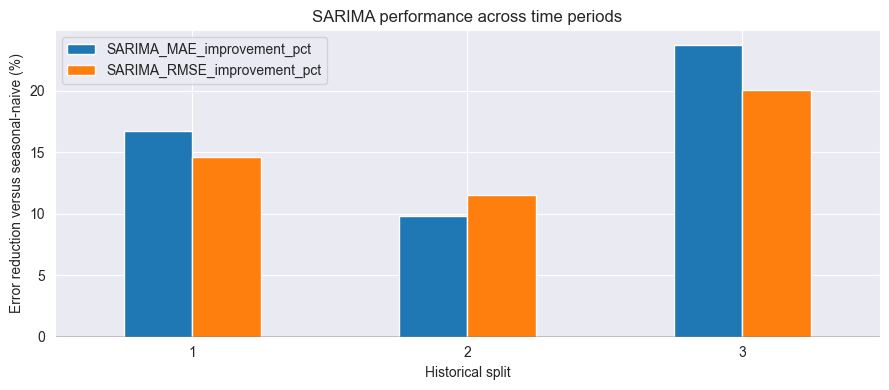

In [156]:
# MAE and RMSE by split
mae = sarima_comparison.pivot(
    index="fold", columns="model", values="MAE"
)
rmse = sarima_comparison.pivot(
    index="fold", columns="model", values="RMSE"
)

split_check = pd.DataFrame({
    "seasonal_naive_MAE": mae["seasonal_naive"],
    "sarima_MAE": mae["sarima"],
    "bilstm_MAE": mae["bilstm"],
    "SARIMA_MAE_improvement_pct": (
        100 * (mae["seasonal_naive"] - mae["sarima"])
        / mae["seasonal_naive"]
    ),
    "SARIMA_RMSE_improvement_pct": (
        100 * (rmse["seasonal_naive"] - rmse["sarima"])
        / rmse["seasonal_naive"]
    ),
})

# Contribution to total absolute-error reduction.
# Negative values indicate a split where SARIMA increased error.
errors = comparison_all.copy()
errors["absolute_error_reduction"] = (
    (errors["actual"] - errors["seasonal_naive"]).abs()
    - (errors["actual"] - errors["sarima"]).abs()
)

contribution = errors.groupby("fold")["absolute_error_reduction"].sum()
total_reduction = contribution.sum()

split_check["total_absolute_error_reduction"] = contribution
split_check["share_of_net_improvement_pct"] = (
    100 * contribution / total_reduction
    if total_reduction > 0 else np.nan
)

print(split_check.round(2).to_string())

wins = (split_check["SARIMA_MAE_improvement_pct"] > 0).sum()
print(
    f"\nSARIMA beats seasonal-naive on MAE "
    f"in {wins} of {len(split_check)} splits."
)

# Plot: positive bars mean SARIMA improves on seasonal-naive.
split_check[
    ["SARIMA_MAE_improvement_pct", "SARIMA_RMSE_improvement_pct"]
].plot.bar(figsize=(9, 4))

plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Error reduction versus seasonal-naive (%)")
plt.xlabel("Historical split")
plt.title("SARIMA performance across time periods")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

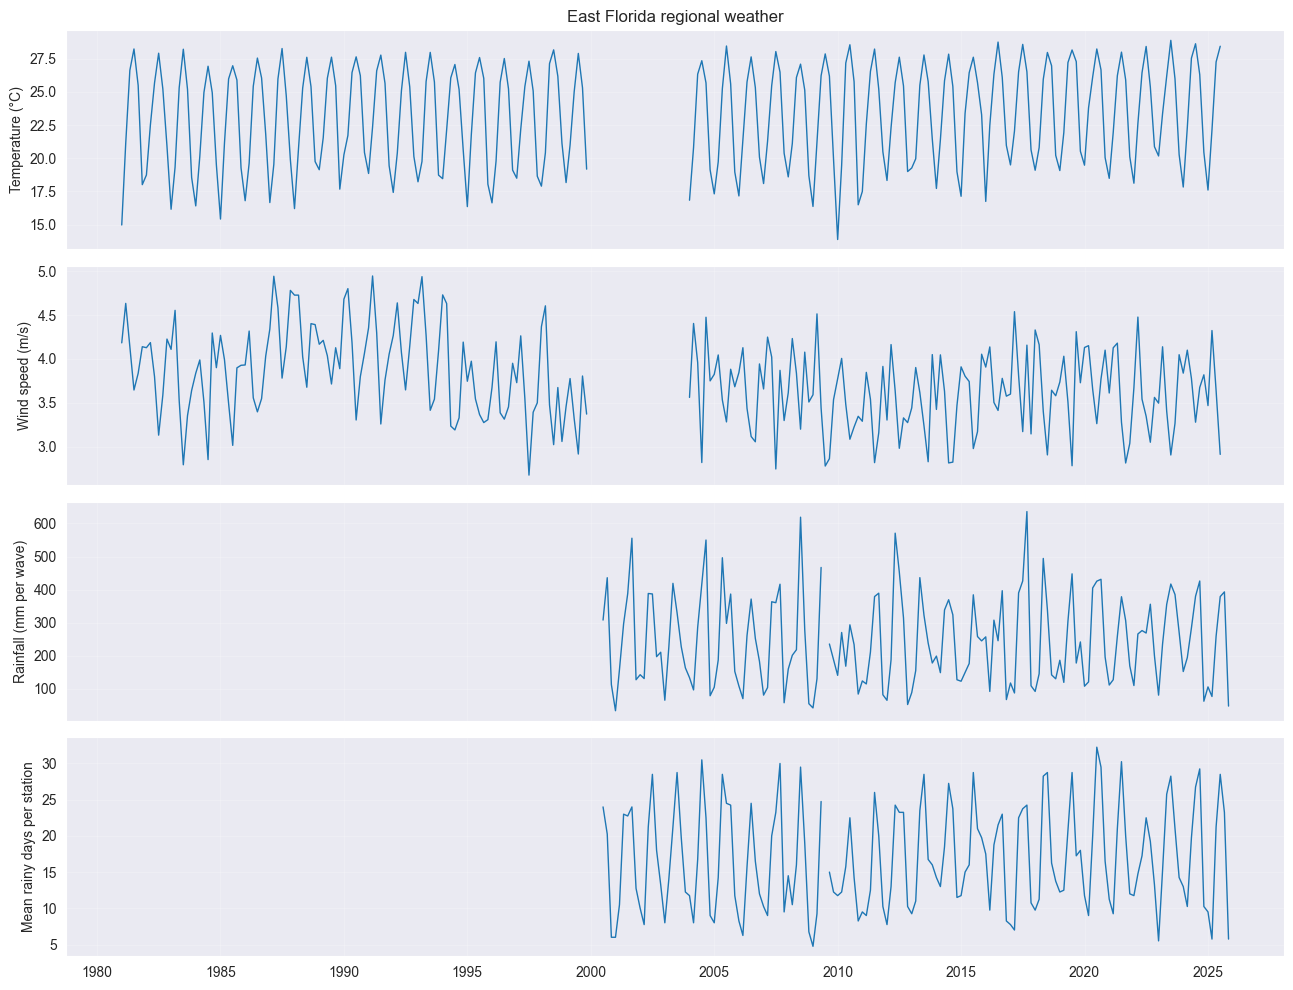

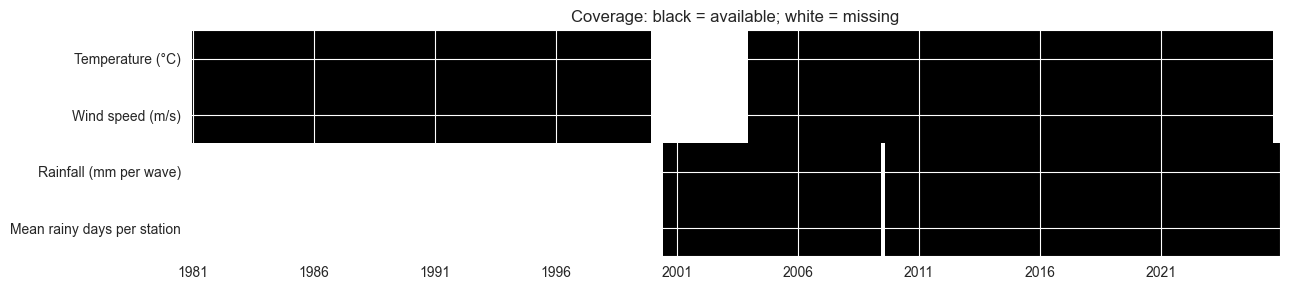

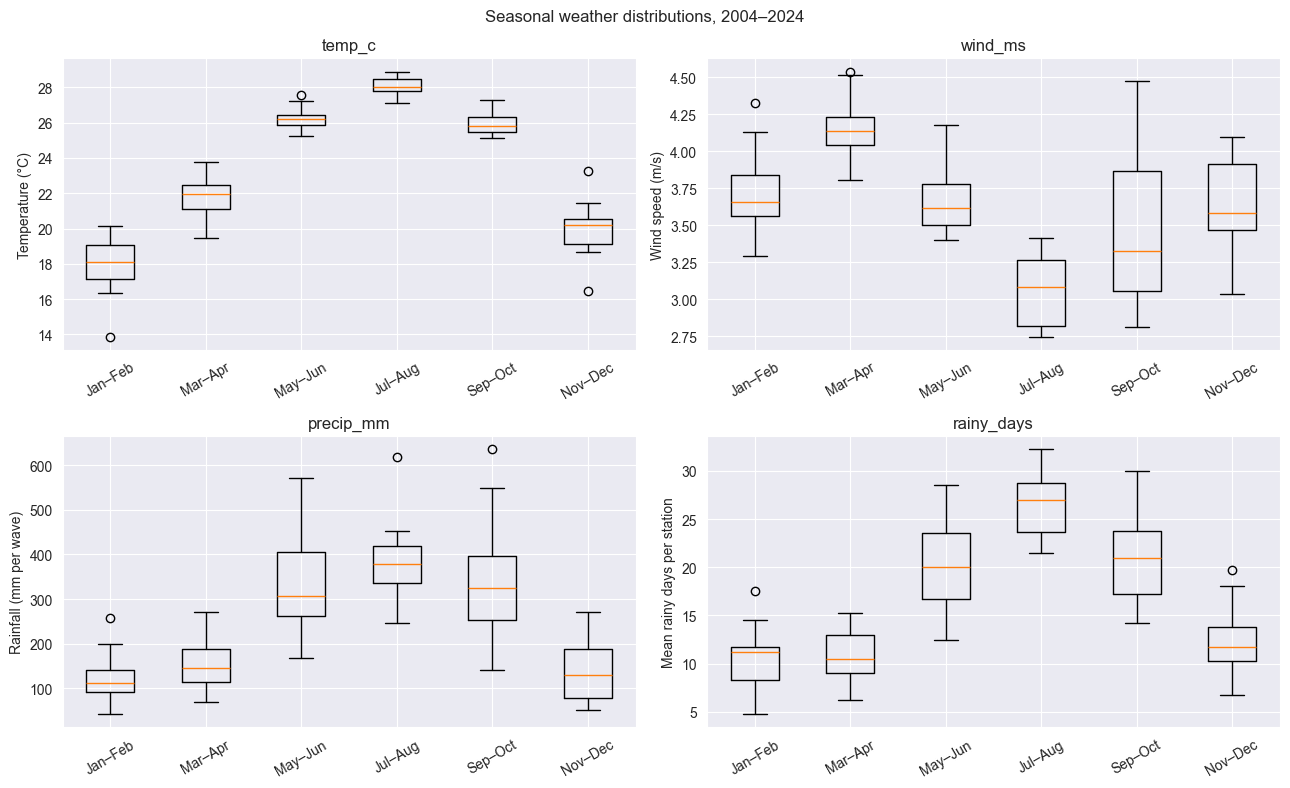

Complete waves for correlation: 125
            temp_c  wind_ms  precip_mm  rainy_days
temp_c       1.000   -0.385      0.732       0.798
wind_ms     -0.385    1.000     -0.321      -0.450
precip_mm    0.732   -0.321      1.000       0.895
rainy_days   0.798   -0.450      0.895       1.000

Correlations after removing average wave seasonality:
            temp_c  wind_ms  precip_mm  rainy_days
temp_c       1.000    0.170     -0.078       0.050
wind_ms      0.170    1.000      0.183       0.175
precip_mm   -0.078    0.183      1.000       0.736
rainy_days   0.050    0.175      0.736       1.000


In [157]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

weather = pd.read_csv(
    "/Users/ilkekosar/PyCharmMiscProject/east_florida_weather.csv",
    parse_dates=["period_start", "period_end"]
).set_index("period_start").sort_index()

variables = ["temp_c", "wind_ms", "precip_mm", "rainy_days"]
labels = {
    "temp_c": "Temperature (°C)",
    "wind_ms": "Wind speed (m/s)",
    "precip_mm": "Rainfall (mm per wave)",
    "rainy_days": "Mean rainy days per station",
}
wave_labels = [
    "Jan–Feb", "Mar–Apr", "May–Jun",
    "Jul–Aug", "Sep–Oct", "Nov–Dec"
]

# 1. Time series: gaps remain visible.
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)

for ax, variable in zip(axes, variables):
    ax.plot(weather.index, weather[variable], linewidth=1)
    ax.set_ylabel(labels[variable])
    ax.grid(alpha=0.2)

axes[0].set_title("East Florida regional weather")
plt.tight_layout()
plt.show()

# 2. Missing-data map.
fig, ax = plt.subplots(figsize=(13, 3))
ax.imshow(
    weather[variables].notna().to_numpy().T,
    aspect="auto",
    interpolation="nearest",
    cmap=plt.get_cmap("Greys", 2),
    vmin=0, vmax=1
)

positions = np.arange(0, len(weather), 30)
ax.set_xticks(positions)
ax.set_xticklabels(weather.index[positions].year)
ax.set_yticks(range(len(variables)))
ax.set_yticklabels([labels[v] for v in variables])
ax.set_title("Coverage: black = available; white = missing")
plt.tight_layout()
plt.show()

# 3. Seasonal distributions over a shared calendar period.
# Each variable still uses its own nonmissing observations.
recent = weather.loc["2004-01-01":"2024-12-31"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, variable in zip(axes.ravel(), variables):
    groups = [
        recent.loc[recent["wave"].eq(w), variable].dropna().to_numpy()
        for w in range(1, 7)
    ]
    ax.boxplot(groups)
    ax.set_xticks(range(1, 7))
    ax.set_xticklabels(wave_labels, rotation=30)
    ax.set_ylabel(labels[variable])
    ax.set_title(variable)

plt.suptitle("Seasonal weather distributions, 2004–2024")
plt.tight_layout()
plt.show()

# 4. Correlations on identical complete observations.
complete = recent[variables].dropna()
print("Complete waves for correlation:", len(complete))
print(complete.corr().round(3))

# Remove average wave seasonality for descriptive exploration.
# This uses the full exploration period; do not use these
# full-period means to transform training/test data for modeling.
wave_means = recent.groupby("wave")[variables].transform("mean")
anomalies = recent[variables] - wave_means

print("\nCorrelations after removing average wave seasonality:")
print(anomalies.dropna().corr().round(3))

In [158]:
import warnings
from itertools import product

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ============================================================
# 1. JOIN EFFORT AND WEATHER
# ============================================================
weather = pd.read_csv(
    "east_florida_weather.csv",
    parse_dates=["period_start"]
).set_index("period_start").sort_index()

effort = pd.to_numeric(ts.copy(), errors="raise")
effort.index = pd.to_datetime(effort.index)

if effort.index.has_duplicates or weather.index.has_duplicates:
    raise ValueError("Duplicate wave-start dates.")

calendar = pd.date_range("2004-01-01", "2024-11-01", freq="2MS")

joined = effort.rename("effort").to_frame().join(
    weather, how="left", validate="one_to_one"
).reindex(calendar)

# Lag columns were created on the full weather calendar.
FEATURES = ["temp_c_lag1", "wind_ms_lag1", "precip_mm_lag1"]

print("Joined waves:", len(joined))
print("Observed effort:", joined["effort"].notna().sum())
print("Missing weather values:")
print(joined[FEATURES].isna().sum())

# ============================================================
# 2. SPLITS AND CANDIDATE ORDERS
# ============================================================
N_SPLITS = 3
TEST_WAVES = 18       # Three years per historical test
VAL_WAVES = 18        # Three years for validation

first_test = len(joined) - N_SPLITS * TEST_WAVES

orders = [(p, 1, q) for p, q in product([0, 1], repeat=2)]
seasonal_orders = [
    (P, 1, Q, 6) for P, Q in product([0, 1], repeat=2)
]

# ============================================================
# 3. TRAINING-ONLY WEATHER PREPROCESSING
# ============================================================
def prepare_weather(fitting_x, all_x):
    fitting_wave = (fitting_x.index.month + 1) // 2
    all_wave = (all_x.index.month + 1) // 2

    medians = fitting_x.groupby(fitting_wave).median()
    fallback = fitting_x.median()

    filled = all_x.copy()

    for column in all_x:
        seasonal_fill = pd.Series(
            [medians[column].get(w, np.nan) for w in all_wave],
            index=all_x.index
        )
        filled[column] = (
            filled[column]
            .fillna(seasonal_fill)
            .fillna(fallback[column])
        )

    if filled.isna().any().any():
        raise ValueError("A weather predictor has no fitting observations.")

    scaler = StandardScaler()
    scaler.fit(filled.loc[fitting_x.index])

    return pd.DataFrame(
        scaler.transform(filled),
        index=filled.index,
        columns=filled.columns
    )

# ============================================================
# 4. FIT AND ROLL FORWARD
# ============================================================
def fit_model(y_fit, order, seasonal_order, x_fit=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        fitted = SARIMAX(
            y_fit,
            exog=x_fit,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(disp=False, maxiter=300)

    if not fitted.mle_retvals.get("converged", False):
        raise RuntimeError("Model did not converge.")

    return fitted

def roll_forward(fitted, actuals, exog=None):
    predictions = []

    for i in range(len(actuals)):
        x_next = None if exog is None else exog.iloc[i:i + 1]

        prediction = float(np.asarray(
            fitted.get_forecast(
                steps=1, exog=x_next
            ).predicted_mean
        )[0])

        predictions.append(max(0.0, prediction))

        # Reveal effort only after predicting this wave.
        fitted = fitted.append(
            actuals.iloc[i:i + 1],
            exog=x_next,
            refit=False
        )

    return pd.Series(predictions, index=actuals.index)

# ============================================================
# 5. SELECT ORDERS ON VALIDATION, THEN EVALUATE
# ============================================================
score_rows = []
prediction_tables = []
selection_rows = []

for fold in range(1, N_SPLITS + 1):
    test_start = first_test + (fold - 1) * TEST_WAVES
    test_end = test_start + TEST_WAVES
    val_start = test_start - VAL_WAVES

    y_fit = joined["effort"].iloc[:val_start]
    y_val = joined["effort"].iloc[val_start:test_start]
    y_test = joined["effort"].iloc[test_start:test_end]

    if y_fit.notna().sum() < 24 or y_val.notna().sum() < 6:
        raise ValueError(f"Insufficient effort history in fold {fold}.")

    # Imputation and scaling fitted before validation.
    x_all = prepare_weather(
        joined[FEATURES].iloc[:val_start],
        joined[FEATURES]
    )
    x_fit = x_all.iloc[:val_start]
    x_val = x_all.iloc[val_start:test_start]
    x_test = x_all.iloc[test_start:test_end]

    comparison = pd.DataFrame({
        "actual": y_test,
        "seasonal_naive": joined["effort"].shift(6).reindex(y_test.index)
    })

    for name, use_weather in [("sarima", False), ("sarimax", True)]:
        best_mae = np.inf
        best_order = None
        best_fitted = None

        for order, seasonal_order in product(orders, seasonal_orders):
            try:
                fitted = fit_model(
                    y_fit, order, seasonal_order,
                    x_fit if use_weather else None
                )

                val_prediction = roll_forward(
                    fitted, y_val,
                    x_val if use_weather else None
                )

                valid = pd.DataFrame({
                    "actual": y_val,
                    "prediction": val_prediction
                }).replace([np.inf, -np.inf], np.nan).dropna()

                if len(valid) != y_val.notna().sum():
                    continue

                val_mae = mean_absolute_error(
                    valid["actual"], valid["prediction"]
                )

                if val_mae < best_mae:
                    best_mae = val_mae
                    best_order = (order, seasonal_order)
                    best_fitted = fitted

            except (ValueError, RuntimeError, np.linalg.LinAlgError):
                continue

        if best_fitted is None:
            raise RuntimeError(f"No valid {name} candidate in fold {fold}.")

        # Update with validation observations, keeping fitted
        # parameters fixed, matching the previous SARIMA protocol.
        updated = best_fitted.append(
            y_val,
            exog=x_val if use_weather else None,
            refit=False
        )

        comparison[name] = roll_forward(
            updated, y_test,
            x_test if use_weather else None
        )

        selection_rows.append({
            "fold": fold,
            "model": name,
            "order": str(best_order),
            "validation_MAE": best_mae
        })

    # Score every model on identical observed dates.
    scored = comparison.replace([np.inf, -np.inf], np.nan).dropna()
    if len(scored) < 2:
        raise ValueError(f"Too few scored dates in fold {fold}.")

    pretest = joined["effort"].iloc[:test_start]
    scale = (pretest - pretest.shift(6)).abs().mean()

    for name in ["seasonal_naive", "sarima", "sarimax"]:
        mae = mean_absolute_error(scored["actual"], scored[name])
        score_rows.append({
            "fold": fold,
            "model": name,
            "MAE": mae,
            "RMSE": np.sqrt(mean_squared_error(
                scored["actual"], scored[name]
            )),
            "seasonal_MASE": (
                mae / scale
                if pd.notna(scale) and scale > 0 else np.nan
            ),
            "n_test": len(scored)
        })

    scored["fold"] = fold
    prediction_tables.append(
        scored.rename_axis("date").reset_index()
    )

    print(
        f"Fold {fold}: {y_test.index.min().date()} to "
        f"{y_test.index.max().date()}"
    )
    print("Test weather values filled:",
          joined[FEATURES].iloc[test_start:test_end].isna().sum().to_dict())

# ============================================================
# 6. RESULTS
# ============================================================
weather_results = pd.DataFrame(score_rows)
weather_predictions = pd.concat(prediction_tables, ignore_index=True)
selected_orders = pd.DataFrame(selection_rows)

print("\nSelected orders:")
print(selected_orders.to_string(index=False))

print("\nResults by split:")
print(weather_results.round(3).to_string(index=False))

pooled = []
for name in ["seasonal_naive", "sarima", "sarimax"]:
    pooled.append({
        "model": name,
        "MAE": mean_absolute_error(
            weather_predictions["actual"], weather_predictions[name]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            weather_predictions["actual"], weather_predictions[name]
        )),
        "n_test": len(weather_predictions)
    })

print("\nPooled results on identical dates:")
print(
    pd.DataFrame(pooled)
    .sort_values("MAE")
    .round(3)
    .to_string(index=False)
)

mae = weather_results.pivot(index="fold", columns="model", values="MAE")
mae["weather_improvement_pct"] = (
    100 * (mae["sarima"] - mae["sarimax"]) / mae["sarima"]
)

print("\nWeather improvement — positive means SARIMAX beats SARIMA:")
print(mae.round(2).to_string())

Joined waves: 126
Observed effort: 126
Missing weather values:
temp_c_lag1       1
wind_ms_lag1      1
precip_mm_lag1    1
dtype: int64
Fold 1: 2016-01-01 to 2018-11-01
Test weather values filled: {'temp_c_lag1': 0, 'wind_ms_lag1': 0, 'precip_mm_lag1': 0}
Fold 2: 2019-01-01 to 2021-11-01
Test weather values filled: {'temp_c_lag1': 0, 'wind_ms_lag1': 0, 'precip_mm_lag1': 0}
Fold 3: 2022-01-01 to 2024-11-01
Test weather values filled: {'temp_c_lag1': 0, 'wind_ms_lag1': 0, 'precip_mm_lag1': 0}

Selected orders:
 fold   model                     order  validation_MAE
    1  sarima ((1, 1, 1), (1, 1, 1, 6))   112578.975689
    1 sarimax ((1, 1, 1), (0, 1, 1, 6))   114756.175141
    2  sarima ((1, 1, 1), (1, 1, 0, 6))   186901.540399
    2 sarimax ((1, 1, 1), (1, 1, 0, 6))   220642.202557
    3  sarima ((0, 1, 1), (1, 1, 1, 6))    92992.055568
    3 sarimax ((0, 1, 1), (1, 1, 1, 6))    95243.153136

Results by split:
 fold          model        MAE       RMSE  seasonal_MASE  n_test
    1 sea

In [159]:
import numpy as np
import pandas as pd

import numpy as np
import pandas as pd
from itertools import product
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

LOOKBACK = 12
VAL_WAVES = 18

# Original effort-only comparison:
# columns: date, fold, actual, seasonal_naive, bilstm, sarima
previous = comparison_all.copy()
previous["date"] = pd.to_datetime(previous["date"])

required = {"date", "fold", "actual", "seasonal_naive", "bilstm", "sarima"}
if not required.issubset(previous.columns):
    raise ValueError(
        "Use comparison_all from the original effort-only comparison."
    )

y = pd.to_numeric(y.copy(), errors="raise").sort_index()
y.index = pd.to_datetime(y.index)

if y.index.has_duplicates:
    raise ValueError("Duplicate effort dates.")

y = y.reindex(
    pd.date_range(y.index.min(), y.index.max(), freq="2MS")
)

# Same original split definition: exclude final 30 waves,
# then evaluate three consecutive 30-wave historical blocks.
ORIGINAL_TEST_WAVES = 30
ORIGINAL_N_SPLITS = 3

first_test = (
    len(y)
    - ORIGINAL_TEST_WAVES
    - ORIGINAL_N_SPLITS * ORIGINAL_TEST_WAVES
)

# Predefine candidates before looking at XGBoost test results.
GRID = list(product(
    [2, 3],           # max_depth
    [0.03, 0.1],      # learning_rate
    [100, 300],       # n_estimators
))

def make_features(series):
    # Lag 1 is the immediately preceding wave.
    # No current-wave effort enters the predictors.
    return pd.DataFrame({
        f"lag_{lag}": series.shift(lag)
        for lag in range(1, LOOKBACK + 1)
    })

X = make_features(y)
def build_xgb(depth, learning_rate, n_estimators):
    return GradientBoostingRegressor(
        loss="squared_error",
        max_depth=depth,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        min_samples_leaf=3,
        subsample=1.0,
        random_state=42,
    )


# Match BiLSTM's log(1 + effort) target and nonnegative output.
def predict_effort(model, features):
    return np.maximum(0, np.expm1(model.predict(features)))

tuning_records = []
selected_records = []
xgb_predictions = []

for fold in range(1, ORIGINAL_N_SPLITS + 1):
    test_start = first_test + (fold - 1) * ORIGINAL_TEST_WAVES
    test_end = test_start + ORIGINAL_TEST_WAVES
    val_start = test_start - VAL_WAVES

    if val_start <= LOOKBACK:
        raise ValueError("Insufficient fitting history.")

    fit_dates = y.index[:val_start]
    val_dates = y.index[val_start:test_start]
    test_dates = y.index[test_start:test_end]

    # Confirm these are the original scored periods.
    recorded_dates = pd.DatetimeIndex(
        previous.loc[previous["fold"].eq(fold), "date"]
    )
    if (
        recorded_dates.empty
        or not recorded_dates.isin(test_dates).all()
    ):
        raise ValueError(
            f"Fold {fold} does not match the original comparison."
        )

    # Skip incomplete windows without closing calendar gaps.
    complete_window = X.notna().all(axis=1)

    fit_mask = (
        X.index.isin(fit_dates)
        & complete_window
        & y.notna()
    )
    val_mask = (
        X.index.isin(val_dates)
        & complete_window
        & y.notna()
    )

    if fit_mask.sum() < 24 or val_mask.sum() < 6:
        raise ValueError(f"Too few complete windows in fold {fold}.")

    X_fit = X.loc[fit_mask]
    target_fit = np.log1p(y.loc[fit_mask])
    X_val = X.loc[val_mask]
    actual_val = y.loc[val_mask]

    best_mae = np.inf
    best_model = None
    best_settings = None

    # --------------------------------------------------------
    # SELECT SETTINGS USING VALIDATION ONLY
    # --------------------------------------------------------
    for depth, learning_rate, n_estimators in GRID:
        model = build_xgb(depth, learning_rate, n_estimators)
        model.fit(X_fit, target_fit)

        validation_prediction = predict_effort(model, X_val)
        val_mae = mean_absolute_error(
            actual_val, validation_prediction
        )

        tuning_records.append({
            "fold": fold,
            "max_depth": depth,
            "learning_rate": learning_rate,
            "n_estimators": n_estimators,
            "validation_MAE": val_mae,
        })

        if val_mae < best_mae:
            best_mae = val_mae
            best_model = model
            best_settings = (depth, learning_rate, n_estimators)

    # --------------------------------------------------------
    # ROLLING ONE-WAVE-AHEAD TEST
    # --------------------------------------------------------
    # Fixed model weights; lag features incorporate observations
    # from earlier test waves only.
    X_test = X.reindex(test_dates)
    usable = X_test.notna().all(axis=1)

    prediction = pd.Series(
        predict_effort(best_model, X_test.loc[usable]),
        index=X_test.index[usable],
    )

    xgb_predictions.append(pd.DataFrame({
        "date": prediction.index,
        "fold": fold,
        "xgboost": prediction.to_numpy(),
    }))

    selected_records.append({
        "fold": fold,
        "max_depth": best_settings[0],
        "learning_rate": best_settings[1],
        "n_estimators": best_settings[2],
        "validation_MAE": best_mae,
    })

    print(
        f"Fold {fold}: depth={best_settings[0]}, "
        f"learning_rate={best_settings[1]}, "
        f"trees={best_settings[2]}, "
        f"validation MAE={best_mae:,.0f}"
    )

# ============================================================
# COMPARE ALL FOUR ON THE ORIGINAL SCORED DATES
# ============================================================
xgb_predictions = pd.concat(xgb_predictions, ignore_index=True)

four_model_predictions = previous.merge(
    xgb_predictions,
    on=["date", "fold"],
    how="left",
    validate="one_to_one",
)

models = ["seasonal_naive", "sarima", "xgboost", "bilstm"]

if not np.isfinite(
    four_model_predictions[["actual"] + models].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Missing/nonfinite predictions on the original scored dates."
    )

# Verify actual values still agree with the current effort series.
np.testing.assert_allclose(
    four_model_predictions["actual"].to_numpy(),
    y.reindex(four_model_predictions["date"]).to_numpy(),
)

rows = []

for fold, group in four_model_predictions.groupby("fold"):
    test_start = first_test + (fold - 1) * ORIGINAL_TEST_WAVES
    history = y.iloc[:test_start]
    scale = (history - history.shift(6)).abs().mean()

    for name in models:
        mae = mean_absolute_error(group["actual"], group[name])

        rows.append({
            "fold": fold,
            "model": name,
            "MAE": mae,
            "RMSE": np.sqrt(mean_squared_error(
                group["actual"], group[name]
            )),
            "seasonal_MASE": (
                mae / scale
                if pd.notna(scale) and scale > 0 else np.nan
            ),
            "n_test": len(group),
        })

four_model_results = pd.DataFrame(rows)

pooled_rows = []
for name in models:
    pooled_rows.append({
        "model": name,
        "MAE": mean_absolute_error(
            four_model_predictions["actual"],
            four_model_predictions[name]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            four_model_predictions["actual"],
            four_model_predictions[name]
        )),
        "n_test": len(four_model_predictions),
    })

pooled_results = pd.DataFrame(pooled_rows).sort_values("MAE")
xgb_tuning = pd.DataFrame(tuning_records)
xgb_selected = pd.DataFrame(selected_records)

print("\nResults by split:")
print(four_model_results.round(3).to_string(index=False))

print("\nPooled performance on identical dates:")
print(pooled_results.round(3).to_string(index=False))

Fold 1: depth=2, learning_rate=0.1, trees=300, validation MAE=143,811
Fold 2: depth=3, learning_rate=0.1, trees=300, validation MAE=180,386
Fold 3: depth=2, learning_rate=0.1, trees=300, validation MAE=124,664

Results by split:
 fold          model        MAE       RMSE  seasonal_MASE  n_test
    1 seasonal_naive 148120.500 186951.778          1.574      30
    1         sarima 123266.456 159607.961          1.310      30
    1        xgboost 208015.019 272747.175          2.211      30
    1         bilstm 208143.235 285860.958          2.212      30
    2 seasonal_naive 144446.333 190860.347          1.396      30
    2         sarima 130271.615 168879.873          1.259      30
    2        xgboost 149462.682 194413.492          1.445      30
    2         bilstm 162691.356 194373.951          1.572      30
    3 seasonal_naive 196212.300 250833.295          1.791      30
    3         sarima 149636.493 200533.629          1.366      30
    3        xgboost 184243.420 227736.324   

In [160]:
from pathlib import Path
import importlib.util

script = Path.home() / "Downloads" / "compare_fishing_series.py"

text = script.read_text()
text = text.replace(
    "validation.notna().to_numpy(dtype=float)",
    "validation.notna().to_numpy(dtype=bool)"
)
script.write_text(text)

assert "validation.notna().to_numpy(dtype=float)" not in text
print("Boolean mask corrected.")

# Reload the edited file.
spec = importlib.util.spec_from_file_location(
    "compare_fishing_series", script
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

results = module.evaluate_fishing_series(df)

Boolean mask corrected.
East shore, fold 1: 30/30 waves scored
East shore, fold 2: 30/30 waves scored
East shore, fold 3: 30/30 waves scored
East private boat, fold 1: 30/30 waves scored
East private boat, fold 2: 30/30 waves scored
East private boat, fold 3: 30/30 waves scored
West shore, fold 1: 30/30 waves scored
West shore, fold 2: 30/30 waves scored
West shore, fold 3: 30/30 waves scored
West private boat, fold 1: 30/30 waves scored
West private boat, fold 2: 30/30 waves scored
West private boat, fold 3: 30/30 waves scored
           series             model        MAE       RMSE  n_test  improvement_vs_seasonal_naive_pct
East private boat            sarima 134222.486 177006.266      90                             17.618
East private boat    seasonal_naive 162926.378 211578.182      90                              0.000
East private boat    bilstm_seed_42 169567.459 209776.994      90                             -4.076
East private boat   bilstm_ensemble 172314.741 213436.814     

MAE by series and split:
model                   seasonal_naive    sarima  gradient_boosting  bilstm_ensemble
series            fold                                                              
East private boat 1           148120.5  123127.5           208015.0         158685.8
                  2           144446.3  129933.5           149462.7         143534.8
                  3           196212.3  149606.5           184243.4         214723.6
East shore        1           373910.4  299620.7           371739.2         354535.1
                  2           578298.5  424132.8           518171.3         438761.8
                  3           884110.6  553203.4           630722.9         564832.8
West private boat 1           167869.5  150853.8           284021.1         199303.6
                  2           160584.4  169444.5           371795.9         247342.6
                  3           179272.3  170568.5           173799.1         166752.8
West shore        1           371428.1  

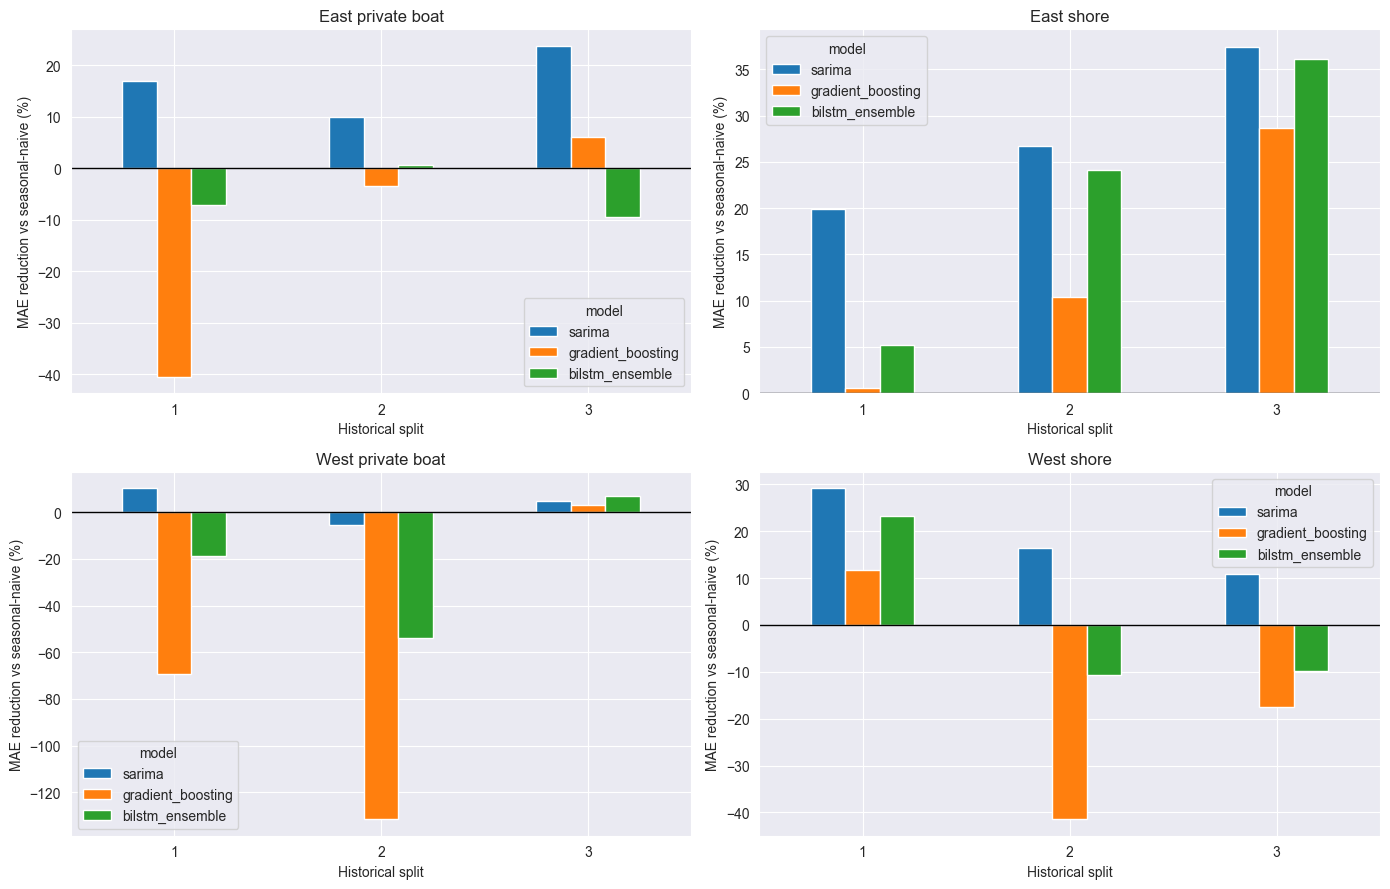


BiLSTM MAE by seed and split:
model                   bilstm_seed_123  bilstm_seed_2026  bilstm_seed_42
series            fold                                                   
East private boat 1            181905.0          168398.9        140813.9
                  2            154352.7          139475.1        162691.4
                  3            234288.2          216266.0        205197.1
East shore        1            393897.3          341229.0        341400.2
                  2            491694.4          412369.7        474372.6
                  3            554580.1          551864.9        633542.5
West private boat 1            218594.0          198576.8        185169.7
                  2            245619.6          290491.7        228013.5
                  3            200967.0          156684.2        153580.4
West shore        1            264044.9          313720.8        307375.7
                  2            405343.1          658959.8        347504.8
       

In [161]:
import pandas as pd
import matplotlib.pyplot as plt

scores = results["scores"].copy()

# Main comparison; individual BiLSTM seeds are shown separately below.
models = [
    "seasonal_naive",
    "sarima",
    "gradient_boosting",
    "bilstm_ensemble",
]

main = scores.loc[scores["model"].isin(models)]

mae = main.pivot(
    index=["series", "fold"], columns="model", values="MAE"
).reindex(columns=models)

rmse = main.pivot(
    index=["series", "fold"], columns="model", values="RMSE"
).reindex(columns=models)

# Verify identical numbers of scored observations.
counts = main.pivot(
    index=["series", "fold"], columns="model", values="n_test"
).reindex(columns=models)

if counts.isna().any().any() or not counts.nunique(axis=1).eq(1).all():
    raise ValueError("Models have missing results or different test counts.")

print("MAE by series and split:")
print(mae.round(1).to_string())

print("\nRMSE by series and split:")
print(rmse.round(1).to_string())

# Positive = lower error than seasonal-naive.
improvement = (
    mae.drop(columns="seasonal_naive")
    .rsub(mae["seasonal_naive"], axis=0)
    .div(mae["seasonal_naive"].where(mae["seasonal_naive"] > 0), axis=0)
    * 100
)

print("\nMAE reduction versus seasonal-naive (%):")
print(improvement.round(2).to_string())

# Include ties rather than silently choosing the first model.
def winners(row):
    minimum = row.min()
    return ", ".join(row.index[row.eq(minimum)])

split_summary = pd.DataFrame({
    "MAE_winner": mae.apply(winners, axis=1),
    "RMSE_winner": rmse.apply(winners, axis=1),
    "SARIMA_beats_baseline": mae["sarima"] < mae["seasonal_naive"],
    "n_test": counts["sarima"],
})

print("\nWinners in each split:")
print(split_summary.to_string())

print("\nNumber of splits SARIMA beats seasonal-naive on MAE:")
print(
    split_summary.groupby(level="series")["SARIMA_beats_baseline"]
    .agg(wins="sum", splits="count")
    .to_string()
)

# Plot improvements separately for each series.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, series in zip(
    axes.ravel(), improvement.index.get_level_values("series").unique()
):
    improvement.xs(series, level="series").plot.bar(ax=ax)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(series)
    ax.set_xlabel("Historical split")
    ax.set_ylabel("MAE reduction vs seasonal-naive (%)")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Individual neural-network seeds: inspect stability by split.
seed_scores = scores.loc[
    scores["model"].str.startswith("bilstm_seed_")
]

print("\nBiLSTM MAE by seed and split:")
print(
    seed_scores.pivot(
        index=["series", "fold"], columns="model", values="MAE"
    ).round(1).to_string()
)

In [162]:
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("fishing_research_checks")
OUT.mkdir(exist_ok=True)

pred = results["predictions"].copy()
pred["date"] = pd.to_datetime(pred["date"])
scores = results["scores"].copy()
tuning = results["tuning"].copy()

# ============================================================
# 1. PAIRED BLOCK-BOOTSTRAP ERROR DIFFERENCES
# ============================================================
# Difference = SARIMA absolute error minus comparator error.
# Negative differences favor SARIMA.
#
# Block lengths represent 6, 12, and 24 months.
# Examine sensitivity rather than choosing the most favorable interval.
BOOTSTRAPS = 5000
BLOCK_LENGTHS = [3, 6, 12]
comparators = [
    "seasonal_naive", "gradient_boosting", "bilstm_ensemble"
]
rng = np.random.default_rng(42)

def bootstrap_fold_differences(values, block_length, repetitions, rng):
    """Circular moving-block resampling within one fold."""
    n = len(values)
    length = min(block_length, n)
    blocks_needed = int(np.ceil(n / length))

    starts = rng.integers(
        0, n, size=(repetitions, blocks_needed)
    )
    indices = (
        starts[:, :, None] + np.arange(length)[None, None, :]
    ) % n

    indices = indices.reshape(repetitions, -1)[:, :n]
    return values[indices].sum(axis=1)

uncertainty_rows = []

for series, group in pred.groupby("series"):
    group = group.sort_values(["fold", "date"])

    for comparator in comparators:
        cols = ["actual", "sarima", comparator]

        if not np.isfinite(group[cols].to_numpy(dtype=float)).all():
            raise ValueError(f"Nonfinite predictions in {series}.")

        sarima_error = (group["actual"] - group["sarima"]).abs()
        comparator_error = (
            group["actual"] - group[comparator]
        ).abs()

        paired = group[["date", "fold"]].copy()
        paired["difference"] = sarima_error - comparator_error

        for length in BLOCK_LENGTHS:
            bootstrap_sum = np.zeros(BOOTSTRAPS)
            n_total = 0

            for fold, fold_data in paired.groupby("fold"):
                fold_data = fold_data.sort_values("date")

                # Do not treat calendar gaps as adjacent waves.
                dates = pd.DatetimeIndex(fold_data["date"])
                expected = pd.date_range(
                    dates.min(), dates.max(), freq="2MS"
                )
                if not dates.equals(expected):
                    raise ValueError(
                        f"{series}, fold {fold}: missing test waves. "
                        "Define contiguous segments before bootstrapping."
                    )

                differences = fold_data["difference"].to_numpy(
                    dtype=float
                )
                bootstrap_sum += bootstrap_fold_differences(
                    differences, length, BOOTSTRAPS, rng
                )
                n_total += len(differences)

            bootstrap_mean = bootstrap_sum / n_total
            lower, upper = np.quantile(
                bootstrap_mean, [0.025, 0.975]
            )
            point = paired["difference"].mean()

            if upper < 0:
                interpretation = "Interval favors SARIMA"
            elif lower > 0:
                interpretation = "Interval favors comparator"
            else:
                interpretation = "Interval includes zero"

            uncertainty_rows.append({
                "series": series,
                "comparator": comparator,
                "block_length_waves": length,
                "n_test": n_total,
                "SARIMA_minus_comparator_MAE": point,
                "interval_95_lower": lower,
                "interval_95_upper": upper,
                "interpretation": interpretation,
            })

uncertainty = pd.DataFrame(uncertainty_rows)

print("\nPaired MAE differences: primary 6-wave blocks")
print(
    uncertainty.loc[uncertainty["block_length_waves"].eq(6)]
    .round(2).to_string(index=False)
)

uncertainty.to_csv(
    OUT / "paired_error_uncertainty.csv", index=False
)

# ============================================================
# 2. TUNING RECORDS AND SELECTED SETTINGS
# ============================================================
# For BiLSTM, settings were selected by mean validation MAE
# across the three predefined seeds.
candidate_summary = (
    tuning.groupby(
        ["series", "fold", "model", "settings"],
        as_index=False
    )
    .agg(
        mean_validation_MAE=("validation_MAE", "mean"),
        runs=("validation_MAE", "size"),
    )
)

if not np.isfinite(
    candidate_summary["mean_validation_MAE"].to_numpy()
).all():
    print("Warning: some candidates were unstable/nonfinite.")

selected_settings = (
    candidate_summary
    .sort_values(
        ["series", "fold", "model",
         "mean_validation_MAE", "settings"]
    )
    .groupby(["series", "fold", "model"], as_index=False)
    .head(1)
)

print("\nSelected settings:")
print(selected_settings.round(2).to_string(index=False))

tuning.to_csv(OUT / "all_validation_runs.csv", index=False)
candidate_summary.to_csv(
    OUT / "validation_candidates.csv", index=False
)
selected_settings.to_csv(
    OUT / "selected_settings.csv", index=False
)

# ============================================================
# 3. BiLSTM SEED VARIABILITY
# ============================================================
# Descriptive variability across seeds—not a confidence interval.
seed_scores = scores.loc[
    scores["model"].str.startswith("bilstm_seed_")
].copy()

seed_variability = (
    seed_scores.groupby(["series", "fold"], as_index=False)
    .agg(
        seeds=("model", "nunique"),
        mean_seed_MAE=("MAE", "mean"),
        sd_seed_MAE=("MAE", "std"),
        min_seed_MAE=("MAE", "min"),
        max_seed_MAE=("MAE", "max"),
    )
)

seed_variability["MAE_range"] = (
    seed_variability["max_seed_MAE"]
    - seed_variability["min_seed_MAE"]
)
seed_variability["MAE_CV_pct"] = (
    100 * seed_variability["sd_seed_MAE"]
    / seed_variability["mean_seed_MAE"]
)

print("\nBiLSTM seed variability:")
print(seed_variability.round(2).to_string(index=False))

seed_scores.to_csv(
    OUT / "individual_seed_scores.csv", index=False
)
seed_variability.to_csv(
    OUT / "seed_variability.csv", index=False
)

# ============================================================
# 4. SAVE FORECAST PROTOCOL AND LIMITATIONS
# ============================================================
protocol = """
Forecast evaluation protocol

Data:
Four Florida inland saltwater/brackish fishing-effort series:
East/West Florida, shore/private-rental boat, area_x=5.
Effort is a survey estimate, not an exact count.
Missing effort remains missing; calendar gaps are never closed.

Historical evaluation:
Three test blocks: 2006-2010, 2011-2015, 2016-2020.
Each contains 30 two-month waves.
Validation comprises the 18 waves immediately preceding each block.
The fitting period expands across folds.
2021-2025 is excluded from these historical comparisons.
That period was previously inspected and is not an untouched holdout.

Forecast assumptions:
Each forecast is one wave ahead.
Earlier observed test effort is used for later test forecasts.
The experiment assumes the preceding effort estimate is available.
Actual MRIP publication delays and historical revisions were not simulated.
Using the final calibrated data vintage may differ from real-time forecasting.

Models:
Seasonal-naive uses effort six waves earlier.
SARIMA parameters are fitted before validation. Validation observations
update its state without re-estimating parameters; test states update likewise.
Gradient boosting and BiLSTM use the preceding 12 waves, with fixed parameters.
They predict log(1 + effort), then back-transform without mean bias correction.
All negative point forecasts are clipped to zero.

Selection:
SARIMA orders and gradient-boosting settings minimize validation MAE.
BiLSTM batch size/learning rate minimize average validation MAE across
seeds 42, 123, and 2026.
BiLSTM early stopping monitors validation loss in scaled log space,
with patience=15 and restored best weights.
The scaler is fitted only on pre-validation effort.
Individual seeds are retained; the ensemble averages their point forecasts.
No seed is selected using test performance.
The historical study design was developed after earlier exploratory results.

Scoring:
Within each series/fold, all models are scored on identical dates with
observed targets, complete 12-wave inputs, and a seasonal-naive prediction.
This common-window rule may exclude dates SARIMA could otherwise forecast.
MAE and RMSE are in angler-trips.
Seasonal MASE uses the mean absolute seasonal difference in pre-test history.
Raw MAE should not be used to rank forecasting difficulty across differently
scaled series without normalized measures.

Uncertainty:
Paired differences are SARIMA absolute error minus comparator absolute error.
Negative values favor SARIMA.
Circular moving blocks are sampled independently inside each fold.
Percentile 95% intervals use 5,000 repetitions and block lengths 3, 6, and 12.
These are exploratory intervals conditional on fitted models and evaluated
periods; they assume dependence is adequately represented by these blocks.
They do not rerun tuning, propagate NOAA survey variance, establish causality,
or adjust for multiple comparisons. Examine block-length sensitivity.
Three neural seeds provide descriptive stability information, not a precise
estimate of the full distribution of training outcomes.

Documentation limitation:
The existing script did not record selected early-stopping epochs or package
versions. Record those in the final reproducibility run.
"""

(OUT / "forecast_protocol.txt").write_text(protocol.strip())

print(f"\nSaved tables and protocol to: {OUT.resolve()}")


Paired MAE differences: primary 6-wave blocks
           series        comparator  block_length_waves  n_test  SARIMA_minus_comparator_MAE  interval_95_lower  interval_95_upper         interpretation
East private boat    seasonal_naive                   6      90                    -28703.89          -51691.30           -6537.88 Interval favors SARIMA
East private boat gradient_boosting                   6      90                    -46351.22          -67335.11          -26277.44 Interval favors SARIMA
East private boat   bilstm_ensemble                   6      90                    -38092.25          -60731.93          -15539.85 Interval favors SARIMA
       East shore    seasonal_naive                   6      90                   -186454.22         -247246.68         -119073.46 Interval favors SARIMA
       East shore gradient_boosting                   6      90                    -81225.52         -143626.06          -21374.40 Interval favors SARIMA
       East shore   bilstm_en

           series calendar_start calendar_end first_observed last_observed  calendar_waves  observed_waves  missing_waves  missing_pct  mean_trips  sd_trips  median_trips  min_trips  max_trips
East private boat     1981-01-01   2025-11-01     1981-03-01    2025-11-01             270             269              1         0.37   554154.63 326682.04      460018.0    61351.0  1501757.0
       East shore     1981-01-01   2025-11-01     1981-03-01    2025-11-01             270             269              1         0.37  1434701.96 623303.17     1334621.0   408986.0  3841118.0
West private boat     1981-01-01   2025-11-01     1981-03-01    2025-11-01             270             269              1         0.37   621770.42 424788.74      552434.0     5508.0  1973067.0
       West shore     1981-01-01   2025-11-01     1981-03-01    2025-11-01             270             269              1         0.37   883353.42 544376.79      758992.0    31600.0  3093210.0


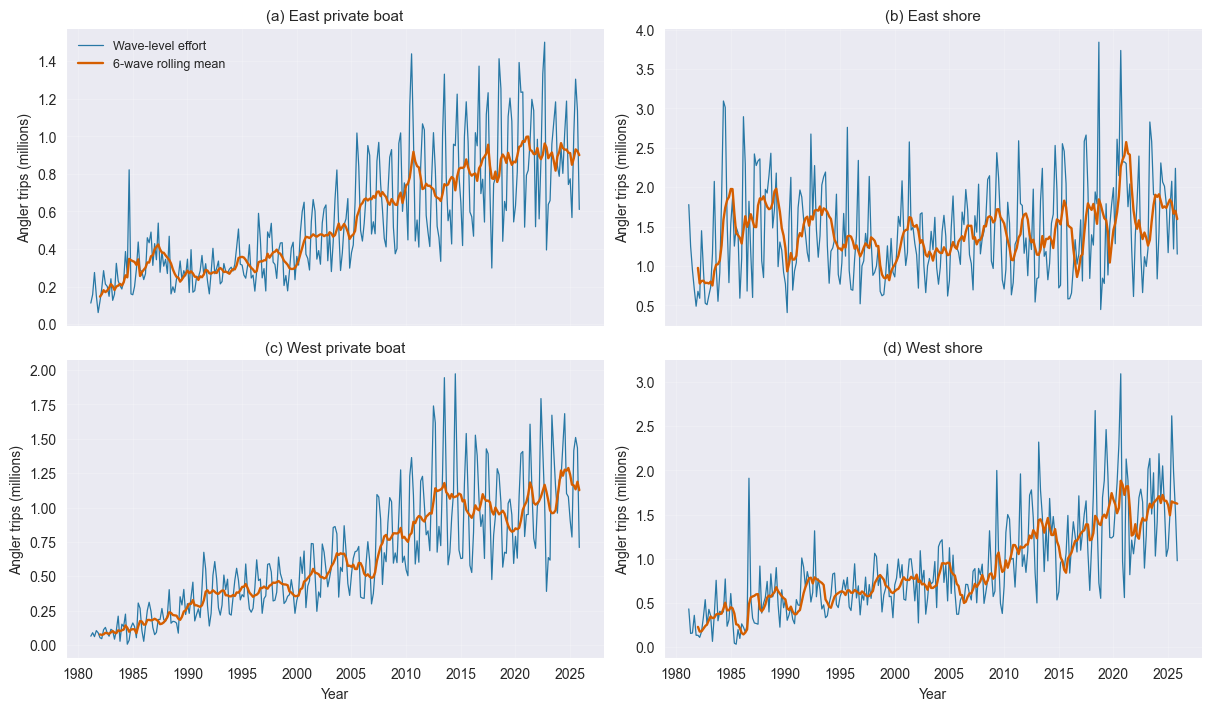

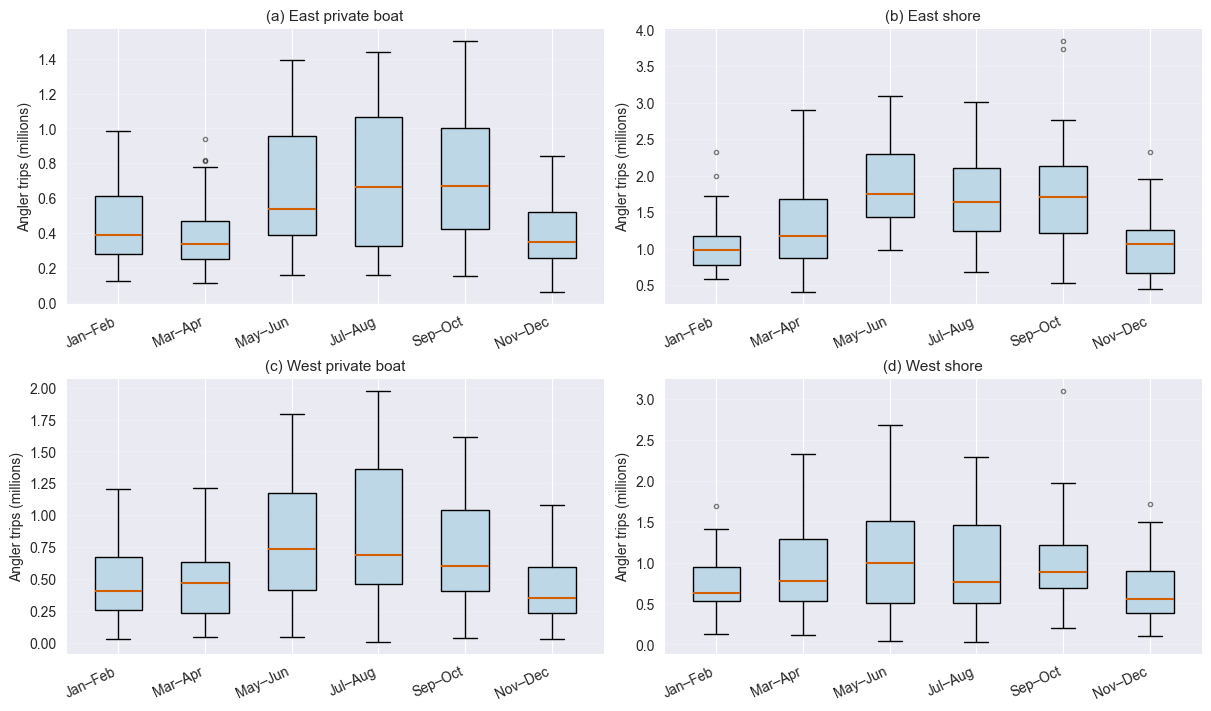


Saved figures and tables in: /Users/ilkekosar/PyCharmMiscProject/fishing_eda


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. SETTINGS — MATCH THE MODELING FILTERS
# ============================================================
OUTPUT = Path("fishing_eda")
OUTPUT.mkdir(parents=True, exist_ok=True)

SERIES = {
    "East private boat": {"sub_reg": 6, "mode_fx": 7},
    "East shore":        {"sub_reg": 6, "mode_fx": 3},
    "West private boat": {"sub_reg": 7, "mode_fx": 7},
    "West shore":        {"sub_reg": 7, "mode_fx": 3},
}

WAVE_LABELS = [
    "Jan–Feb", "Mar–Apr", "May–Jun",
    "Jul–Aug", "Sep–Oct", "Nov–Dec"
]

# ============================================================
# 2. CLEAN NUMERIC FIELDS
# Commas in these MRIP values are thousands separators:
# "1,650,495" becomes 1650495.0.
# ============================================================
data = df.copy()
required = ["year", "wave", "st", "sub_reg", "mode_fx", "area_x", "estrips"]

missing_columns = set(required) - set(data.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

for col in required:
    raw = data[col]
    cleaned = (
        raw.astype("string")
        .str.strip()
        .str.replace(",", "", regex=False)
    )
    converted = pd.to_numeric(cleaned, errors="coerce")

    # Do not silently discard unfamiliar nonnumeric values.
    missing_tokens = cleaned.str.upper().isin(
        ["", "NA", "N/A", "NAN", "NONE", "NULL", ".", "--"]
    )
    invalid = raw.notna() & ~missing_tokens & converted.isna()

    if invalid.any():
        examples = raw.loc[invalid].astype(str).unique()[:5]
        raise ValueError(
            f"Unrecognized values in {col}: {examples.tolist()}. "
            "Check their source meaning before treating them as missing."
        )

    data[col] = converted.astype("float64")

selected = data.loc[
    data["st"].eq(12)
    & data["area_x"].eq(5)
    & data["sub_reg"].isin([6, 7])
    & data["mode_fx"].isin([3, 7])
].copy()

if selected.empty:
    raise ValueError("No records match the four modeling series.")

for col in ["year", "wave"]:
    values = selected[col]
    if values.isna().any() or (values % 1 != 0).any():
        raise ValueError(f"{col} contains missing or noninteger values.")

if not selected["wave"].between(1, 6).all():
    raise ValueError("Wave must be between 1 and 6.")

if selected["estrips"].dropna().lt(0).any():
    raise ValueError("Negative effort estimates found; inspect the source rows.")

selected["year"] = selected["year"].astype(int)
selected["wave"] = selected["wave"].astype(int)

selected["date"] = pd.to_datetime({
    "year": selected["year"],
    "month": 2 * selected["wave"] - 1,
    "day": 1
})

# Shared calendar includes all six waves in every selected year.
first_year = selected["year"].min()
last_year = selected["year"].max()
calendar = pd.date_range(
    start=f"{first_year}-01-01",
    end=f"{last_year}-11-01",
    freq="2MS"
)

# ============================================================
# 3. BUILD FOUR REGULAR SERIES AND SUMMARY TABLE
# ============================================================
series_data = {}
summary_rows = []

for name, filters in SERIES.items():
    subset = selected.loc[
        selected["sub_reg"].eq(filters["sub_reg"])
        & selected["mode_fx"].eq(filters["mode_fx"])
    ].copy()

    if subset.empty:
        raise ValueError(f"No records found for {name}.")

    duplicates = subset.duplicated(["year", "wave"], keep=False)
    if duplicates.any():
        example = subset.loc[
            duplicates, ["year", "wave", "estrips"]
        ].head(10)
        raise ValueError(
            f"Duplicate year–wave records in {name}.\n"
            f"{example.to_string(index=False)}\n"
            "Resolve overlapping archives/status records before plotting."
        )

    y = subset.set_index("date")["estrips"].sort_index()
    y = y.reindex(calendar).rename(name)
    observed = y.dropna()

    if observed.empty:
        raise ValueError(f"No observed effort estimates for {name}.")

    series_data[name] = y

    summary_rows.append({
        "series": name,
        "calendar_start": calendar.min().date(),
        "calendar_end": calendar.max().date(),
        "first_observed": observed.index.min().date(),
        "last_observed": observed.index.max().date(),
        "calendar_waves": len(y),
        "observed_waves": y.notna().sum(),
        "missing_waves": y.isna().sum(),
        "missing_pct": 100 * y.isna().mean(),
        "mean_trips": observed.mean(),
        "sd_trips": observed.std(ddof=1),
        "median_trips": observed.median(),
        "min_trips": observed.min(),
        "max_trips": observed.max()
    })

summary = pd.DataFrame(summary_rows)
effort = pd.DataFrame(series_data)
effort.index.name = "date"

summary.to_csv(OUTPUT / "eda_summary_four_series.csv", index=False)
effort.to_csv(OUTPUT / "eda_four_series_effort.csv")

print(summary.round(2).to_string(index=False))

# ============================================================
# 4. FIGURE: EFFORT OVER TIME
# Missing values remain gaps.
# Rolling mean requires six consecutive observed waves.
# ============================================================
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.facecolor": "white"
})

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True,
    constrained_layout=True
)

for panel, (ax, (name, y)) in enumerate(
    zip(axes.flat, series_data.items())
):
    ax.plot(
        y.index, y / 1e6,
        color="#2878A5", linewidth=0.9,
        label="Wave-level effort"
    )
    rolling = y.rolling(window=6, min_periods=6).mean()
    ax.plot(
        rolling.index, rolling / 1e6,
        color="#D55E00", linewidth=1.7,
        label="6-wave rolling mean"
    )
    ax.set_title(f"({chr(97 + panel)}) {name}")
    ax.set_ylabel("Angler trips (millions)")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[-1]:
    ax.set_xlabel("Year")

axes[0, 0].legend(frameon=False, fontsize=9)
fig.savefig(OUTPUT / "effort_time_series_four_panels.png", dpi=300)
fig.savefig(OUTPUT / "effort_time_series_four_panels.pdf")
plt.show()

# ============================================================
# 5. FIGURE: SEASONAL DISTRIBUTIONS
# Each box summarizes observed estimates for that wave
# across years; missing estimates are excluded.
# ============================================================
fig, axes = plt.subplots(
    2, 2, figsize=(12, 7),
    constrained_layout=True
)

for panel, (ax, (name, y)) in enumerate(
    zip(axes.flat, series_data.items())
):
    wave = (y.index.month + 1) // 2
    groups = [
        y.loc[wave == w].dropna().to_numpy(dtype=float) / 1e6
        for w in range(1, 7)
    ]

    # Plot only waves with observed estimates.
    positions = [i + 1 for i, g in enumerate(groups) if len(g)]
    observed_groups = [g for g in groups if len(g)]

    boxes = ax.boxplot(
        observed_groups,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        medianprops={"color": "#D55E00", "linewidth": 1.5},
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.5}
    )
    for box in boxes["boxes"]:
        box.set_facecolor("#BDD7E7")

    ax.set_xticks(range(1, 7))
    ax.set_xticklabels(WAVE_LABELS, rotation=25, ha="right")
    ax.set_xlim(0.4, 6.6)
    ax.set_title(f"({chr(97 + panel)}) {name}")
    ax.set_ylabel("Angler trips (millions)")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(OUTPUT / "seasonality_four_panels.png", dpi=300)
fig.savefig(OUTPUT / "seasonality_four_panels.pdf")
plt.show()

print(f"\nSaved figures and tables in: {OUTPUT.resolve()}")

In [25]:
df

,status,year,wave,sub_reg,sub_reg_f,st,st_f,mode_fx,mode_fx_f,area_x,...,pse_e,lower_estrips,upper_estrips,mrip_std_estrips,stat_sig_estrips,source_archive,source_member,period_start,period_end,estrips_original
0,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,3,SHORE,1,...,41.6,304747.5,2996243.3,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30,"1,650,495"
1,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,3,SHORE,5,...,40.7,359986.9,3199306.2,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30,"1,779,647"
2,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,6,PARTY/CHARTER BOAT,1,...,40.4,3100.9,26692.4,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30,"14,897"
3,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,6,PARTY/CHARTER BOAT,2,...,41.2,2554.7,23990.3,CAUTION,YES,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30,"13,272"
4,FINAL,1981,2,6,SOUTH ATLANTIC,12,FLORIDA,7,PRIVATE/RENTAL BOAT,1,...,56.9,0.0,207061.7,NO,NO,mrip_effort_bywave_1981_1989_csv.zip,mrip_effort_bywave_1981.csv,1981-03-01,1981-04-30,"97,890"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4191,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,5,CHARTER BOAT,4,...,18.0,24517.6,51247.6,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31,"37,883"
4192,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,5,CHARTER BOAT,5,...,17.1,16813.8,33766.1,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31,"25,290"
4193,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,7,PRIVATE/RENTAL BOAT,3,...,23.8,186886.3,513692.0,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31,"350,289"
4194,FINAL,2025,6,7,GULF OF AMERICA,12,FLORIDA,7,PRIVATE/RENTAL BOAT,4,...,23.5,126995.4,343881.1,YES,YES,mrip_effort_bywave_2025.csv,mrip_effort_bywave_2025.csv,2025-11-01,2025-12-31,"235,438"


In [29]:
import pandas as pd

# Use the full fishing dataset, containing both coasts and modes.
data = df.copy()

required = [
    "year", "wave", "st", "sub_reg",
    "mode_fx", "area_x", "estrips"
]

missing = set(required) - set(data.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# MRIP commas are thousands separators: "1,650,495" → 1650495.
for col in required:
    cleaned = (
        data[col].astype("string")
        .str.strip()
        .str.replace(",", "", regex=False)
    )
    numeric = pd.to_numeric(cleaned, errors="coerce")

    missing_tokens = cleaned.str.upper().isin(
        ["", "NA", "N/A", "NAN", "NONE", "NULL", ".", "--"]
    )
    invalid = cleaned.notna() & ~missing_tokens & numeric.isna()

    if invalid.any():
        examples = cleaned.loc[invalid].unique()[:5].tolist()
        raise ValueError(f"Check nonnumeric values in {col}: {examples}")

    data[col] = numeric.astype("float64")

definitions = {
    "East private boat": (6, 7),
    "East shore":        (6, 3),
    "West private boat": (7, 7),
    "West shore":        (7, 3),
}

data = data.loc[
    data["st"].eq(12)
    & data["area_x"].eq(5)
    & data["sub_reg"].isin([6, 7])
    & data["mode_fx"].isin([3, 7])
].copy()

if data.empty:
    raise ValueError(
        "No matching records. Use the original full fishing dataframe."
    )

for col in ["year", "wave"]:
    if data[col].isna().any() or (data[col] % 1 != 0).any():
        raise ValueError(f"{col} contains missing or noninteger values.")

if not data["wave"].between(1, 6).all():
    raise ValueError("Wave must be between 1 and 6.")

data["date"] = pd.to_datetime({
    "year": data["year"].astype(int),
    "month": 2 * data["wave"].astype(int) - 1,
    "day": 1
})

calendar = pd.date_range(
    f"{int(data['year'].min())}-01-01",
    f"{int(data['year'].max())}-11-01",
    freq="2MS"
)

series_data = {}

for name, (region, mode) in definitions.items():
    subset = data.loc[
        data["sub_reg"].eq(region)
        & data["mode_fx"].eq(mode)
    ]

    if subset.empty:
        raise ValueError(f"{name} is missing from df.")

    if subset["date"].duplicated().any():
        raise ValueError(
            f"{name} has duplicate year–wave records. "
            "Resolve overlapping source records before decomposition."
        )

    y = (
        subset.set_index("date")["estrips"]
        .sort_index()
        .reindex(calendar)
        .rename(name)
    )

    if y.dropna().lt(0).any():
        raise ValueError(f"{name} contains negative effort estimates.")

    series_data[name] = y
    print(f"{name}: {y.notna().sum()} observed / {len(y)} calendar waves")

East private boat: 269 observed / 270 calendar waves
East shore: 269 observed / 270 calendar waves
West private boat: 269 observed / 270 calendar waves
West shore: 269 observed / 270 calendar waves


East private boat: decomposition uses 269 waves, 1981-03 to 2025-11
East shore: decomposition uses 269 waves, 1981-03 to 2025-11
West private boat: decomposition uses 269 waves, 1981-03 to 2025-11
West shore: decomposition uses 269 waves, 1981-03 to 2025-11


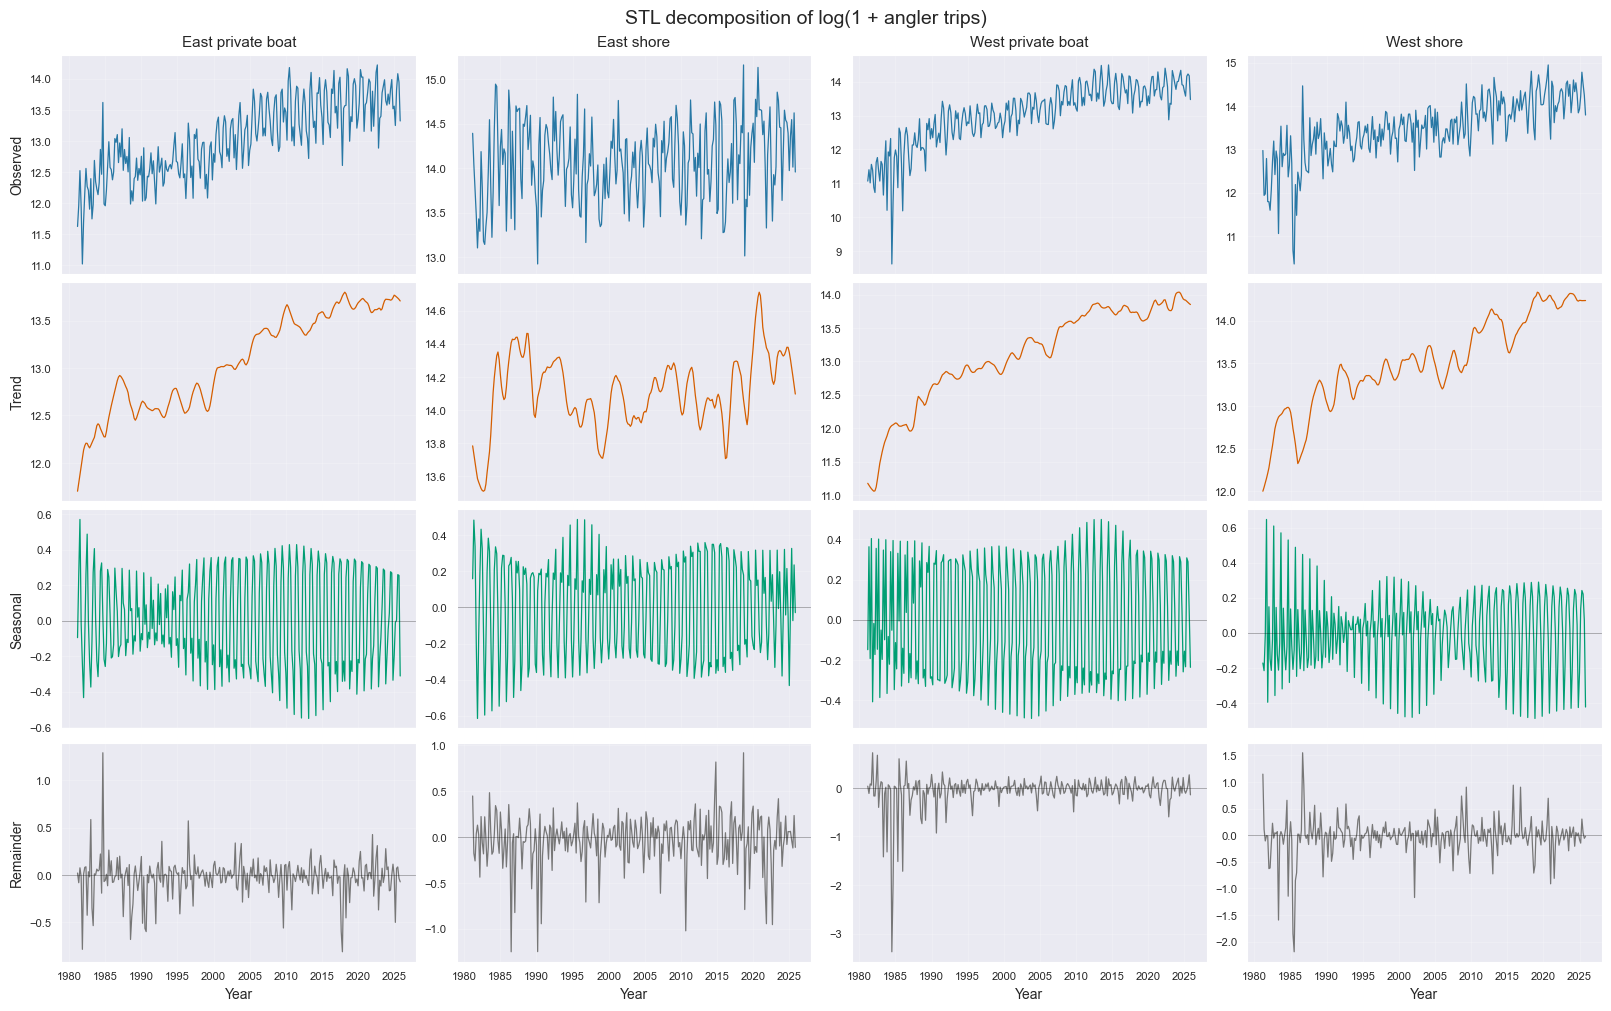

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from pathlib import Path

output = Path("fishing_eda")
output.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

fields = ["observed", "trend", "seasonal", "remainder"]
labels = ["Observed", "Trend", "Seasonal", "Remainder"]
colors = ["#2878A5", "#D55E00", "#009E73", "#777777"]

for col, (name, original) in enumerate(series_data.items()):
    y = original.sort_index().astype(float)

    # Select the longest uninterrupted observed segment.
    observed = y.notna()
    groups = observed.ne(observed.shift()).cumsum()
    segments = [
        segment
        for _, segment in y.groupby(groups)
        if segment.notna().all()
    ]

    if not segments:
        raise ValueError(f"No observed data for {name}.")

    y = max(segments, key=len)

    if len(y) < 12:
        raise ValueError(f"{name}: fewer than 12 consecutive waves.")
    if not np.isfinite(y.to_numpy()).all() or (y < 0).any():
        raise ValueError(f"{name}: check invalid or negative effort.")

    transformed = np.log1p(y)
    result = STL(
        transformed,
        period=6,
        seasonal=13,
        robust=True
    ).fit()

    components = pd.DataFrame({
        "observed": transformed,
        "trend": result.trend,
        "seasonal": result.seasonal,
        "remainder": result.resid
    })

    for row, field in enumerate(fields):
        ax = axes[row, col]
        ax.plot(
            components.index,
            components[field],
            color=colors[row],
            linewidth=0.9
        )

        if row == 0:
            ax.set_title(name, fontsize=11)
        if col == 0:
            ax.set_ylabel(labels[row])
        if row == 3:
            ax.set_xlabel("Year")
        if row >= 2:
            ax.axhline(0, color="black", linewidth=0.5, alpha=0.4)

        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=8)

    print(
        f"{name}: decomposition uses {len(y)} waves, "
        f"{y.index.min():%Y-%m} to {y.index.max():%Y-%m}"
    )

fig.suptitle("STL decomposition of log(1 + angler trips)", fontsize=14)
fig.savefig(output / "stl_four_series.png", dpi=300)
fig.savefig(output / "stl_four_series.pdf")

plt.show()

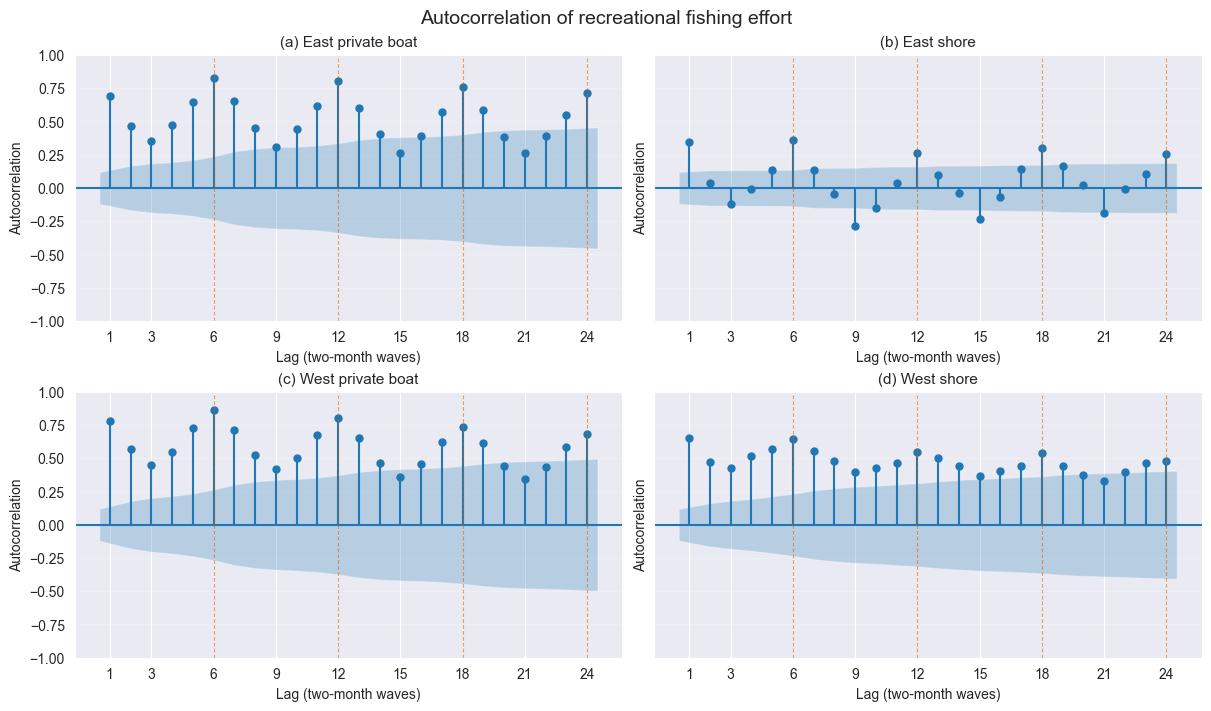

           series      start        end  waves_used  maximum_lag
East private boat 1981-03-01 2025-11-01         269           24
       East shore 1981-03-01 2025-11-01         269           24
West private boat 1981-03-01 2025-11-01         269           24
       West shore 1981-03-01 2025-11-01         269           24


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path

output = Path("fishing_eda")
output.mkdir(parents=True, exist_ok=True)

names = [
    "East private boat",
    "East shore",
    "West private boat",
    "West shore"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 7),
    sharey=True,
    constrained_layout=True
)

coverage = []

for panel, (ax, name) in enumerate(zip(axes.flat, names)):
    y = series_data[name].sort_index().astype(float)

    # Ensure absent calendar waves are represented as missing.
    calendar = pd.date_range(
        y.index.min(), y.index.max(), freq="2MS"
    )
    y = y.reindex(calendar)

    # Select longest consecutive observed segment.
    observed = y.notna()
    groups = observed.ne(observed.shift()).cumsum()
    segments = [
        segment
        for _, segment in y.groupby(groups)
        if segment.notna().all()
    ]

    if not segments:
        raise ValueError(f"No observed estimates for {name}.")

    y = max(segments, key=len)

    if len(y) < 12:
        raise ValueError(f"{name}: fewer than 12 consecutive waves.")
    if not np.isfinite(y.to_numpy()).all() or (y < 0).any():
        raise ValueError(f"{name}: check invalid or negative effort.")
    if y.nunique() < 2:
        raise ValueError(f"{name}: ACF is undefined for a constant series.")

    max_lag = min(24, len(y) - 1)

    plot_acf(
        y.to_numpy(),
        lags=max_lag,
        alpha=0.05,
        zero=False,
        bartlett_confint=True,
        ax=ax
    )

    # Six two-month waves correspond to one year.
    for lag in range(6, max_lag + 1, 6):
        ax.axvline(
            lag, color="#D55E00",
            linestyle="--", linewidth=0.8, alpha=0.6
        )

    ax.set_title(f"({chr(97 + panel)}) {name}")
    ax.set_xlabel("Lag (two-month waves)")
    ax.set_ylabel("Autocorrelation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(
        sorted(set([1] + list(range(3, max_lag + 1, 3))))
    )
    ax.grid(axis="y", alpha=0.2)

    coverage.append({
        "series": name,
        "start": y.index.min().date(),
        "end": y.index.max().date(),
        "waves_used": len(y),
        "maximum_lag": max_lag
    })

fig.suptitle(
    "Autocorrelation of recreational fishing effort",
    fontsize=14
)

fig.savefig(output / "acf_four_series.png", dpi=300)
fig.savefig(output / "acf_four_series.pdf")
plt.show()

coverage = pd.DataFrame(coverage)
coverage.to_csv(output / "acf_four_series_coverage.csv", index=False)
print(coverage.to_string(index=False))